# NLP - Airline Tweet Analytics
Airlines receive large volumes of customer feedback through social
media. Manually reviewing every tweet is time-consuming, so this project
explores how Natural Language Processing (NLP) and Machine Learning can
automatically classify customer opinions as **negative, neutral, or
positive**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re

from collections import Counter

import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.stem import PorterStemmer

# Set the visualization style
sns.set_style("whitegrid")

# Set figure size style
plt.rcParams["figure.figsize"] = (10, 5)

# 1.1 Theory Notes: NLP Fundamentals

### 1. What is NLP?

Natural Language Processing (NLP) is a branch of Artificial Intelligence that enables computers to understand, process, analyse and interpret human languages such as English and Hindi.

**Why do businesses need NLP?**

Businesses use NLP to analyse customer feedback, automate communication, understand customer opinions and extract useful information from large amounts of text data.

**Three real-world applications:**

1. **Voice Assistants:** Google Assistant and Alexa understand human voice commands.
2. **Spam Detection:** Email services identify unwanted and suspicious messages.
3. **Language Translation:** Google Translate converts text from one language into another.

### 2. Four Challenges in NLP

1. **Ambiguity:** A word can have different meanings depending on the sentence.
   - Example: "I went to the bank." Bank can mean a financial institution or a riverbank.

2. **Sarcasm:** People sometimes express the opposite of what they actually mean.
   - Example: "Great! Another three-hour flight delay."

3. **Slang:** Informal words and short forms are difficult for computers to understand.
   - Example: "The service was lit."

4. **Spelling Mistakes and Hinglish:** Users often write incorrect spellings or mix different languages.
   - Example: "Flight late hai, service bahut bad hai."

### 3. Stages of a Basic NLP Pipeline

1. Raw Text Collection
2. Text Cleaning
3. Tokenization
4. Stopword Removal
5. Stemming or Lemmatization
6. Feature Extraction
7. Model Training
8. Prediction and Evaluation

**Conclusion:** NLP helps businesses understand customer communication and make better decisions using text data.

# Step 1.2: Load and Explore Dataset

In [2]:
df = pd.read_csv("Tweets.csv")

df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## Select the four required columns

In [3]:
df = df[['airline', 'airline_sentiment', 'negativereason', 'text']]

df.head()

,airline,airline_sentiment,negativereason,text
0,Virgin America,neutral,NaN,@VirginAmerica What @dhepburn said.
1,Virgin America,positive,NaN,@VirginAmerica plus you've added commercials t...
2,Virgin America,neutral,NaN,@VirginAmerica I didn't today... Must mean I n...
3,Virgin America,negative,Bad Flight,@VirginAmerica it's really aggressive to blast...
4,Virgin America,negative,Can't Tell,@VirginAmerica and it's a really big bad thing...


## Check dataset shape

In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (14640, 4)


## Check Information

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   airline            14640 non-null  str  
 1   airline_sentiment  14640 non-null  str  
 2   negativereason     9178 non-null   str  
 3   text               14640 non-null  str  
dtypes: str(4)
memory usage: 2.3 MB


In [6]:
df.describe()

,airline,airline_sentiment,negativereason,text
count,14640,14640,9178,14640
unique,6,3,10,14427
top,United,negative,Customer Service Issue,@united thanks
freq,3822,9178,2910,6


## Check Missing value

In [7]:
print(df.isnull().sum())

airline                 0
airline_sentiment       0
negativereason       5462
text                    0
dtype: int64


## Count each airline sentiment

In [8]:
sentiment_count = df['airline_sentiment'].value_counts()

print(sentiment_count)

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


## Plot sentiment distribution

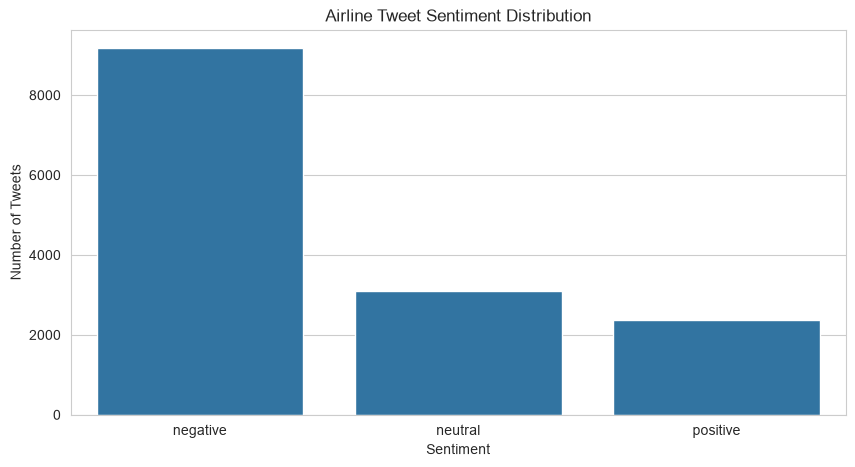

In [9]:
sns.countplot(
    data=df,
    x='airline_sentiment',
    order=['negative', 'neutral', 'positive']
)

plt.title("Airline Tweet Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.show()

## Calculate negative tweet percentage

In [10]:
negative_count = (df['airline_sentiment'] == 'negative').sum()

total_tweets = len(df)

negative_percentage = (negative_count / total_tweets) * 100

print("Total Tweets:", total_tweets)
print("Negative Tweets:", negative_count)

print("Negative Tweet Percentage:",round(negative_percentage, 2), "%")

Total Tweets: 14640
Negative Tweets: 9178
Negative Tweet Percentage: 62.69 %


## Why is negative sentiment a warning sign?
### Interpretation

Negative sentiment is an important warning sign because it indicates customer dissatisfaction with airline services.

A high percentage of negative tweets may indicate problems related to flight delays, cancellations, baggage handling and customer service.

Therefore, airlines should analyse negative feedback and identify the main reasons for customer complaints to improve customer satisfaction.

## Sentiment distribution for each airline

In [11]:
airline_sentiment = pd.crosstab(
    df['airline'],
    df['airline_sentiment']
)

print(airline_sentiment)

airline_sentiment  negative  neutral  positive
airline                                       
American               1960      463       336
Delta                   955      723       544
Southwest              1186      664       570
US Airways             2263      381       269
United                 2633      697       492
Virgin America          181      171       152


## Plot grouped sentiment distribution

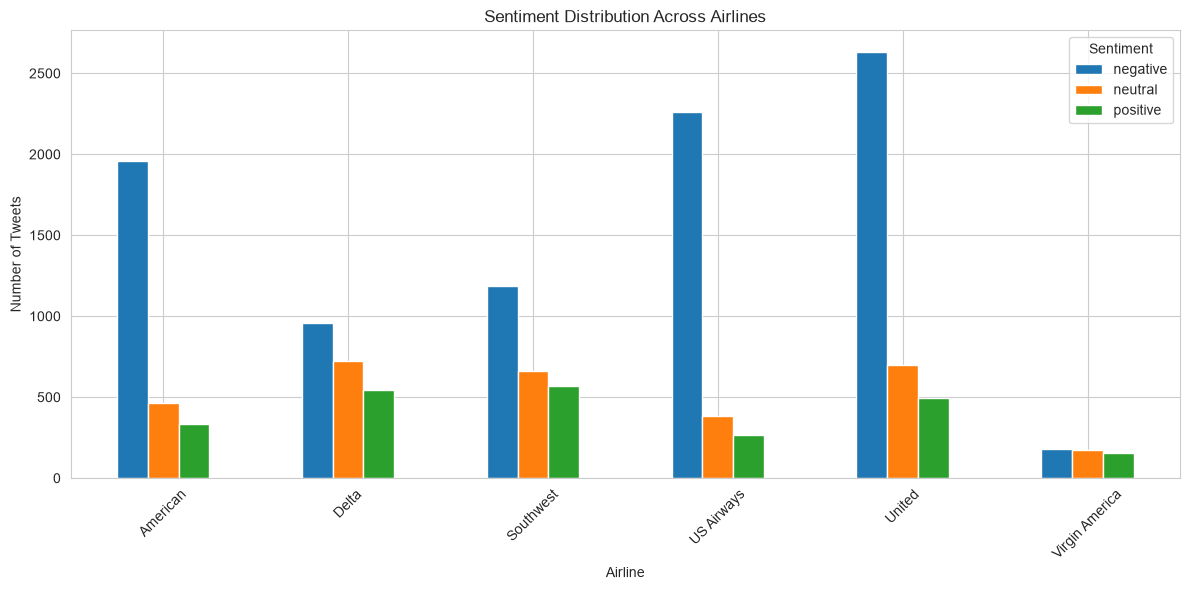

In [12]:
airline_sentiment.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Sentiment Distribution Across Airlines")
plt.xlabel("Airline")

plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)

plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

## Find the airline with the highest share of negative tweets

In [13]:
airline_total = df.groupby('airline').size()

airline_negative = df[df['airline_sentiment'] == 'negative'].groupby('airline').size()

negative_share = (airline_negative / airline_total) * 100

negative_share = negative_share.sort_values(ascending=False)

print("Negative Tweet Percentage by Airline:")
print(negative_share.round(2))

print("\nAirline with Highest Negative Share:",negative_share.idxmax())

print("Negative Percentage:",round(negative_share.max(), 2), "%")

Negative Tweet Percentage by Airline:
airline
US Airways        77.69
American          71.04
United            68.89
Southwest         49.01
Delta             42.98
Virgin America    35.91
dtype: float64

Airline with Highest Negative Share: US Airways
Negative Percentage: 77.69 %


## Average tweet length

In [14]:
df['tweet_length'] = df['text'].apply(lambda x: len(str(x).split()))

average_length = df.groupby('airline_sentiment')['tweet_length'].mean()

print("Average Tweet Length:")
print(average_length.round(2))

Average Tweet Length:
airline_sentiment
negative    19.69
neutral     14.41
positive    14.01
Name: tweet_length, dtype: float64


## Visualize average tweet length

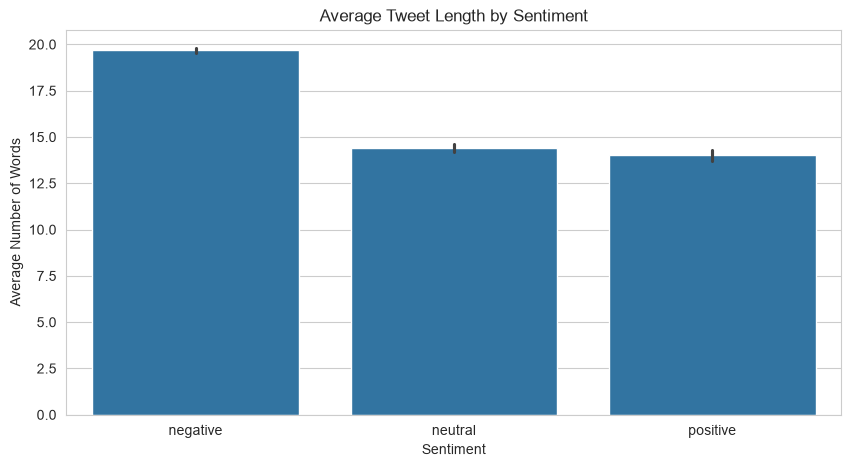

In [15]:
sns.barplot(
    data=df,
    x='airline_sentiment',
    y='tweet_length',
    order=['negative', 'neutral', 'positive'],
    estimator='mean'
)

plt.title("Average Tweet Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Number of Words")
plt.show()

# Step 1.3: Regular Expressions (RegEx)
## Extract all @mentions

In [16]:
all_mentions = []

for tweet in df['text'].dropna():

    mentions = re.findall(r'@\w+', tweet)

    all_mentions.extend(mentions)

mention_count = Counter(all_mentions)

print("Total Mentions:", len(all_mentions))
print("\nTop 5 Most Used Mentions:")

for mention, count in mention_count.most_common(5):
    print(mention, ":", count)

Total Mentions: 16507

Top 5 Most Used Mentions:
@united : 3765
@AmericanAir : 2926
@USAirways : 2907
@SouthwestAir : 2409
@JetBlue : 2198


## Extract all hashtags

In [17]:
all_hashtags = []

for tweet in df['text'].dropna():

    hashtags = re.findall(r'#\w+', tweet)

    all_hashtags.extend(hashtags)

hashtag_count = Counter(all_hashtags)

print("Total Hashtags:", len(all_hashtags))
print("\nTop 5 Most Used Hashtags:")

for hashtag, count in hashtag_count.most_common(5):
    print(hashtag, ":", count)

Total Hashtags: 3502

Top 5 Most Used Hashtags:
#DestinationDragons : 75
#fail : 57
#jetblue : 35
#UnitedAirlines : 35
#customerservice : 34


## Find tweets containing URLs

In [18]:
url_pattern = r'https?://\S+'

url_tweets = df[df['text'].str.contains(
    url_pattern,
    case=False,
    regex=True,
    na=False
)]

url_count = len(url_tweets)

url_negative_count = (
    url_tweets['airline_sentiment'] == 'negative').sum()

if url_count > 0:
    url_negative_percentage = (
        url_negative_count / url_count
    ) * 100
else:
    url_negative_percentage = 0

print("Tweets Containing URLs:", url_count)

print("Negative Tweets Among URL Tweets:",url_negative_count)

print("Negative Percentage:",
      round(url_negative_percentage, 2), "%")

Tweets Containing URLs: 1173
Negative Tweets Among URL Tweets: 448
Negative Percentage: 38.19 %


## Find flight numbers

In [19]:
flight_pattern = r'(?i)\bflight\s*#?\s*\d+\b'

all_flights = []

for tweet in df['text'].dropna():

    flights = re.findall(flight_pattern, tweet)
    all_flights.extend(flights)

print("Total Flight Number Mentions:", len(all_flights))
print("\nThree Flight Number Examples:")

for flight in all_flights[:3]:
    print(flight)

Total Flight Number Mentions: 612

Three Flight Number Examples:
flight 89
flight 2
flight 769


## Replace mentions and URLs

In [20]:
df['modified_text'] = df['text'].copy()

df['modified_text'] = df['modified_text'].str.replace(
    r'@\w+',
    'USER',
    regex=True
)

df['modified_text'] = df['modified_text'].str.replace(
    r'https?://\S+',
    'LINK',
    regex=True
)

for i in range(3):

    print("\nOriginal Tweet:")
    print(df['text'].iloc[i])

    print("\nModified Tweet:")
    print(df['modified_text'].iloc[i])

    print("-" * 70)


Original Tweet:
@VirginAmerica What @dhepburn said.

Modified Tweet:
USER What USER said.
----------------------------------------------------------------------

Original Tweet:
@VirginAmerica plus you've added commercials to the experience... tacky.

Modified Tweet:
USER plus you've added commercials to the experience... tacky.
----------------------------------------------------------------------

Original Tweet:
@VirginAmerica I didn't today... Must mean I need to take another trip!

Modified Tweet:
USER I didn't today... Must mean I need to take another trip!
----------------------------------------------------------------------


# Step 1.4: Text Preprocessing Pipeline
## Initialize preprocessing tools

In [21]:
lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words('english'))

stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

print("Total Stopwords:", len(stop_words))

print("\nNegation words retained:",'not', 'no', 'nor')

Total Stopwords: 195

Negation words retained: not no nor


## Create clean_text() function

In [22]:
def clean_text(text):

    text = str(text)

    text = text.lower()

    # Remove @mentions
    text = re.sub(r'@\w+', ' ', text)

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove # symbol but keep hashtag words
    text = re.sub(r'#', '', text)

    # Remove numbers and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    tokens = word_tokenize(text)

    cleaned_tokens = []

    for word in tokens:

        if word not in stop_words:

            lemma = lemmatizer.lemmatize(word)

            cleaned_tokens.append(lemma)

    cleaned_text = ' '.join(cleaned_tokens)

    return cleaned_text

## Apply cleaning function to the dataset

In [23]:
df['clean_text'] = df['text'].apply(clean_text)

df[['text', 'clean_text']].head()

,text,clean_text
0,@VirginAmerica What @dhepburn said.,said
1,@VirginAmerica plus you've added commercials t...,plus added commercial experience tacky
2,@VirginAmerica I didn't today... Must mean I n...,today must mean need take another trip
3,@VirginAmerica it's really aggressive to blast...,really aggressive blast obnoxious entertainmen...
4,@VirginAmerica and it's a really big bad thing...,really big bad thing


## Compare original and cleaned text for five tweets

In [24]:
for i in range(5):

    print("\nOriginal Text:")
    print(df['text'].iloc[i])

    print("\nCleaned Text:")
    print(df['clean_text'].iloc[i])

    print("=" * 80)


Original Text:
@VirginAmerica What @dhepburn said.

Cleaned Text:
said

Original Text:
@VirginAmerica plus you've added commercials to the experience... tacky.

Cleaned Text:
plus added commercial experience tacky

Original Text:
@VirginAmerica I didn't today... Must mean I need to take another trip!

Cleaned Text:
today must mean need take another trip

Original Text:
@VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse

Cleaned Text:
really aggressive blast obnoxious entertainment guest face amp little recourse

Original Text:
@VirginAmerica and it's a really big bad thing about it

Cleaned Text:
really big bad thing


## Check cleaned dataset

In [25]:
print(df['clean_text'].head())

0                                                 said
1               plus added commercial experience tacky
2               today must mean need take another trip
3    really aggressive blast obnoxious entertainmen...
4                                 really big bad thing
Name: clean_text, dtype: str


In [26]:
print("Missing Values in Cleaned Text:")
print(df['clean_text'].isnull().sum())

print("\nDataset Shape:", df.shape)

Missing Values in Cleaned Text:
0

Dataset Shape: (14640, 7)


# Step 1.5: Stemming vs Lemmatization
## Initialize stemmer and lemmatizer

In [27]:
stemmer = PorterStemmer()

lemmatizer = WordNetLemmatizer()

words = [
    'delayed',
    'cancelled',
    'flying',
    'flights',
    'waiting',
    'lost',
    'bags',
    'thanks'
]

## Compare stemming and lemmatization

In [28]:
results = []

for word in words:

    stem_word = stemmer.stem(word)

    lemma_word = lemmatizer.lemmatize(word)

    results.append({
        'Original Word': word,
        'Porter Stem': stem_word,
        'WordNet Lemma': lemma_word
    })

comparison_df = pd.DataFrame(results)

comparison_df

,Original Word,Porter Stem,WordNet Lemma
0,delayed,delay,delayed
1,cancelled,cancel,cancelled
2,flying,fli,flying
3,flights,flight,flight
4,waiting,wait,waiting
5,lost,lost,lost
6,bags,bag,bag
7,thanks,thank,thanks


# 1.5 Stemming vs Lemmatization

### Stemming

Stemming is a text preprocessing technique that removes prefixes or suffixes from words to produce a shorter root-like form.

Example:
- Delayed → delay
- Flights → flight
- Waiting → wait

### Lemmatization

Lemmatization converts a word into its meaningful dictionary base form using vocabulary and linguistic rules.

Example:
- Bags → bag
- Flights → flight
- Better → good (with appropriate POS information)

### Difference

| Stemming | Lemmatization |
|---|---|
| Removes word endings | Finds dictionary base form |
| May produce non-dictionary words | Usually produces meaningful words |
| Faster | Comparatively slower |
| Less linguistically accurate | More linguistically accurate |

**Conclusion:**

Stemming is suitable for a quick prototype because it is simple and fast. Lemmatization is more suitable for a polished NLP product because it generally produces meaningful words and preserves linguistic information.

# Step 1.6: Word Frequency Analysis
In this section, we identify the 15 most frequent words in negative and positive tweets.

We will use:
- Counter() to count words.
- clean_text column for cleaned tweets.
- matplotlib to create horizontal bar charts.

## Find top 15 words in negative tweets

In [29]:
negative_tweets = df[
    df['airline_sentiment'] == 'negative'
]

negative_words = []

for tweet in negative_tweets['clean_text']:

    words_list = tweet.split()

    negative_words.extend(words_list)

negative_word_count = Counter(negative_words)

top_negative_words = negative_word_count.most_common(15)

negative_freq_df = pd.DataFrame(
    top_negative_words,
    columns=['Word', 'Frequency']
)

print("Top 15 Words in Negative Tweets:")
print(negative_freq_df)

Top 15 Words in Negative Tweets:
         Word  Frequency
0      flight       3378
1         not       1401
2          no       1327
3        hour       1116
4         get       1017
5   cancelled        926
6    customer        783
7     service        772
8           u        762
9        time        749
10        bag        664
11       help        622
12       hold        616
13      plane        601
14       call        511


## Visualize negative word frequency

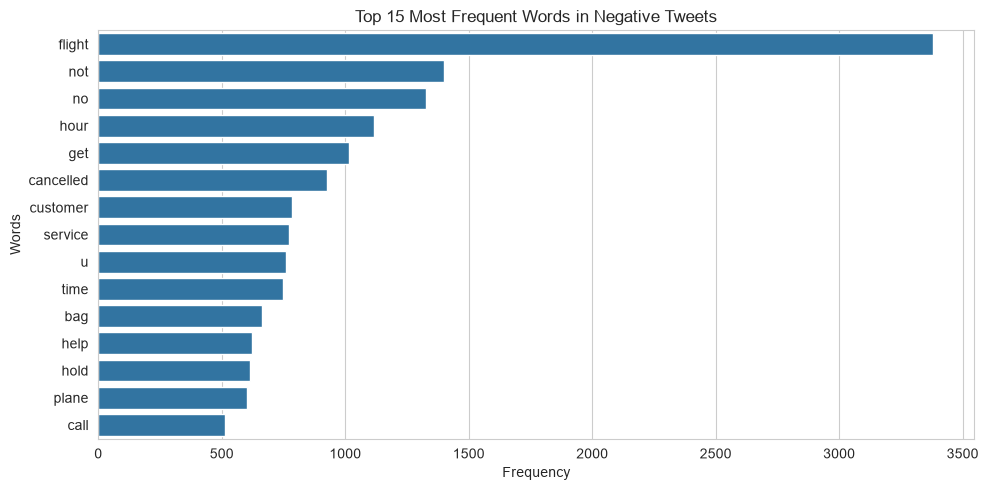

In [30]:
sns.barplot(
    data=negative_freq_df,
    x='Frequency',
    y='Word'
)

plt.title("Top 15 Most Frequent Words in Negative Tweets")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.show()

## Find top 15 words in positive tweets

In [31]:
positive_tweets = df[
    df['airline_sentiment'] == 'positive']

positive_words = []

for tweet in positive_tweets['clean_text']:

    words_list = tweet.split()

    positive_words.extend(words_list)

positive_word_count = Counter(positive_words)

top_positive_words = positive_word_count.most_common(15)

positive_freq_df = pd.DataFrame(
    top_positive_words,
    columns=['Word', 'Frequency']
)

print("Top 15 Words in Positive Tweets:")
print(positive_freq_df)

Top 15 Words in Positive Tweets:
        Word  Frequency
0     thanks        611
1      thank        455
2     flight        442
3      great        236
4    service        164
5          u        137
6       love        136
7   customer        124
8        guy        123
9        get        120
10      good        110
11      time        109
12      much        109
13   airline        107
14      best        105


## Visualize positive word frequency

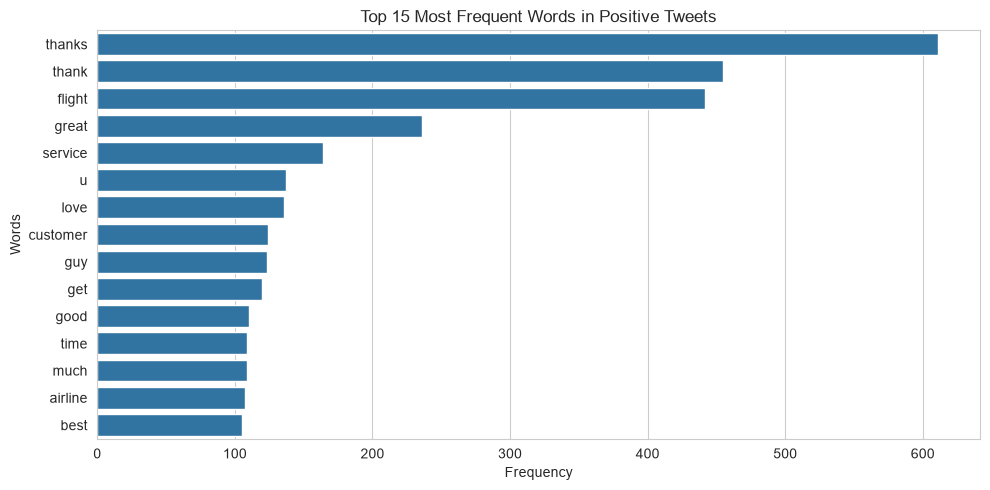

In [32]:
sns.barplot(
    data=positive_freq_df,
    x='Frequency',
    y='Word'
)

plt.title("Top 15 Most Frequent Words in Positive Tweets")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.show()

## Find common words in both sentiments

In [33]:
negative_word_set = set(negative_word_count.keys())

positive_word_set = set(positive_word_count.keys())

common_words = negative_word_set.intersection(
    positive_word_set
)

print("Words Appearing in Both Sentiments:")

for word in sorted(common_words):
    print(word)

Words Appearing in Both Sentiments:
aa
ability
able
aboard
abq
absolute
absolutely
absurd
abt
accept
accepted
access
accident
accommodate
accommodating
accommodation
account
acct
accurate
acknowledge
acknowledgement
acknowledgment
across
act
action
actually
ad
adam
add
added
adding
addition
additional
address
addtl
admiral
admit
advance
advantage
advertising
advice
affect
affected
afford
afternoon
age
agent
ago
agree
agt
ah
ahead
ahhhh
air
airbus
aircraft
airfare
airline
airplane
airport
airway
aka
al
albany
alcohol
alert
alive
alliance
allowing
allows
almost
along
already
alright
also
although
always
amazed
amazing
america
american
americanair
americanairlines
americanview
among
amount
amp
ana
andrew
angeles
angry
anniversary
announced
announcement
annual
another
answer
answered
answering
anthony
anticipate
antonio
anxious
anybody
anyone
anything
anytime
anyway
anywhere
ap
apart
apologize
apologizing
apology
app
apparently
appears
appease
apple
applied
appreciate
appreciated
appreciat

# 1.6 Word Frequency Analysis

### Interpretation

The word frequency analysis helps identify common topics and patterns in positive and negative airline tweets.

**Negative Tweets:**

Words such as delay, cancelled, flight, service and customer may indicate passenger dissatisfaction related to flight delays, cancellations and customer service.

**Positive Tweets:**

Words such as thanks, great, good, service and thank may indicate customer satisfaction and appreciation of airline services.

**Common Words:**

Some words appear in both positive and negative tweets because they describe general airline-related topics. Their meaning depends on the surrounding words and sentence context.

**Conclusion:**

Word frequency analysis provides a basic understanding of customer opinions. However, frequency alone cannot determine sentiment because the same word can appear in both positive and negative contexts.

##  Display final dataset 


In [155]:
print("Final Dataset Shape:", df.shape)

# Display all columns
print("\nDataset Columns:")
print(df.columns.tolist())

# Check important columns
print("\nRequired Columns Verification:")

print("airline:", 'airline' in df.columns)
print("airline_sentiment:", 'airline_sentiment' in df.columns)
print("negativereason:", 'negativereason' in df.columns)
print("text:", 'text' in df.columns)
print("tweet_length:", 'tweet_length' in df.columns)
print("clean_text:", 'clean_text' in df.columns)

Final Dataset Shape: (14640, 9)

Dataset Columns:
['airline', 'airline_sentiment', 'negativereason', 'text', 'tweet_length', 'modified_text', 'clean_text', 'tokens', 'token_count']

Required Columns Verification:
airline: True
airline_sentiment: True
negativereason: True
text: True
tweet_length: True
clean_text: True


In [ ]:
# Display sentiment distribution
print("\nSentiment Distribution:")
print(df['airline_sentiment'].value_counts())

# Display five cleaned tweets
print("\nSample Cleaned Tweets:")
print(df[['text', 'clean_text']].head())

print("\n COMPLETED SUCCESSFULLY!")


Sentiment Distribution:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Sample Cleaned Tweets:
                                                text  \
0                @VirginAmerica What @dhepburn said.   
1  @VirginAmerica plus you've added commercials t...   
2  @VirginAmerica I didn't today... Must mean I n...   
3  @VirginAmerica it's really aggressive to blast...   
4  @VirginAmerica and it's a really big bad thing...   

                                          clean_text  
0                                               said  
1             plus added commercial experience tacky  
2             today must mean need take another trip  
3  really aggressive blast obnoxious entertainmen...  
4                               really big bad thing  

 COMPLETED SUCCESSFULLY!


# Step 2: Feature Extraction: Bag-of-Words, TF-IDF & N-Grams

In [35]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

from IPython.display import display

## 2.1: Bag-of-Words (BoW) on the Tiny Corpus

In [36]:
documents = [
    "flight was on time",
    "flight was late",
    "great crew and great service",
    "not happy with the service"
]

for i, doc in enumerate(documents, start=1):
    print(f"Document {i}: {doc}")

Document 1: flight was on time
Document 2: flight was late
Document 3: great crew and great service
Document 4: not happy with the service


## Apply CountVectorizer

In [37]:
bow_vectorizer = CountVectorizer()

bow_matrix = bow_vectorizer.fit_transform(documents)

print("Vocabulary:")
print(bow_vectorizer.get_feature_names_out())

Vocabulary:
['and' 'crew' 'flight' 'great' 'happy' 'late' 'not' 'on' 'service' 'the'
 'time' 'was' 'with']


## Print document-term matrix

In [38]:
bow_array = bow_matrix.toarray()

print("Bag-of-Words Matrix:")
print(bow_array)

Bag-of-Words Matrix:
[[0 0 1 0 0 0 0 1 0 0 1 1 0]
 [0 0 1 0 0 1 0 0 0 0 0 1 0]
 [1 1 0 2 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 1 0 1 1 0 0 1]]


## Convert matrix into Pandas DataFrame

In [39]:
bow_features = bow_vectorizer.get_feature_names_out()

bow_df = pd.DataFrame(
    bow_array,
    columns=bow_features,
    index=['Doc 1', 'Doc 2', 'Doc 3', 'Doc 4']
)

display(bow_df)

,and,crew,flight,great,happy,late,not,on,service,the,time,was,with
Doc 1,0,0,1,0,0,0,0,1,0,0,1,1,0
Doc 2,0,0,1,0,0,1,0,0,0,0,0,1,0
Doc 3,1,1,0,2,0,0,0,0,1,0,0,0,0
Doc 4,0,0,0,0,1,0,1,0,1,1,0,0,1


## 2.1 Bag-of-Words (BoW) Interpretation

Bag-of-Words is a feature extraction technique that converts text into numerical values by counting how many times each word appears in a document.

**Explanation:**

- Each column represents a unique word from the vocabulary.
- Each row represents a document.
- Each number represents the frequency of a word in that document.
- A value of 0 means that the word does not appear in that document.
- A value greater than 0 represents the number of occurrences.

**Example:**

Document 3 is "great crew and great service".

The word "great" appears twice, so its value in the matrix is 2.

**What does BoW ignore?**

Bag-of-Words ignores grammar, word order and the context of words. It only considers word frequency.

**Conclusion:** BoW is a simple and useful technique for converting text into numerical features for machine learning.

# 2.2: TF-IDF on the Tiny Corpus
## Apply TfidfVectorizer

In [40]:
tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

print("TF-IDF Vocabulary:")
print(tfidf_vectorizer.get_feature_names_out())

TF-IDF Vocabulary:
['and' 'crew' 'flight' 'great' 'happy' 'late' 'not' 'on' 'service' 'the'
 'time' 'was' 'with']


## Print TF-IDF matrix

In [41]:
tfidf_array = tfidf_matrix.toarray()

print("TF-IDF Matrix:")
print(np.round(tfidf_array, 2))

TF-IDF Matrix:
[[0.   0.   0.44 0.   0.   0.   0.   0.56 0.   0.   0.56 0.44 0.  ]
 [0.   0.   0.53 0.   0.   0.67 0.   0.   0.   0.   0.   0.53 0.  ]
 [0.39 0.39 0.   0.78 0.   0.   0.   0.   0.31 0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.47 0.   0.47 0.   0.37 0.47 0.   0.   0.47]]


## Convert TF-IDF matrix into DataFrame

In [42]:
tfidf_features = tfidf_vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(
    np.round(tfidf_array, 2),
    columns=tfidf_features,
    index=['Doc 1', 'Doc 2', 'Doc 3', 'Doc 4']
)

display(tfidf_df)

,and,crew,flight,great,happy,late,not,on,service,the,time,was,with
Doc 1,0.00,0.00,0.44,0.00,0.00,0.00,0.00,0.56,0.00,0.00,0.56,0.44,0.00
Doc 2,0.00,0.00,0.53,0.00,0.00,0.67,0.00,0.00,0.00,0.00,0.00,0.53,0.00
Doc 3,0.39,0.39,0.00,0.78,0.00,0.00,0.00,0.00,0.31,0.00,0.00,0.00,0.00
Doc 4,0.00,0.00,0.00,0.00,0.47,0.00,0.47,0.00,0.37,0.47,0.00,0.00,0.47


## Compare flight and crew weights
The assignment specifically asks you to compare:
- flight: Appears in two documents.
- crew: Appears in one document.

In [43]:
idf_values = tfidf_vectorizer.idf_

idf_df = pd.DataFrame({
    'Word': tfidf_vectorizer.get_feature_names_out(),
    'IDF Score': idf_values
})

comparison = idf_df[idf_df['Word'].isin(['flight', 'crew'])]

print("Flight vs Crew IDF Comparison:")
display(comparison)

Flight vs Crew IDF Comparison:


,Word,IDF Score
1,crew,1.916291
2,flight,1.510826


## Compare average TF-IDF scores

In [44]:
average_tfidf = tfidf_df.mean(axis=0)

selected_words = average_tfidf[['flight', 'crew']]

print("Average TF-IDF Scores:")
print(selected_words.round(4))

print("\nWord with Higher Average TF-IDF:")
print(selected_words.idxmax())

Average TF-IDF Scores:
flight    0.2425
crew      0.0975
dtype: float64

Word with Higher Average TF-IDF:
flight


## 2.2 TF-IDF Theory

TF-IDF stands for Term Frequency-Inverse Document Frequency. It measures the importance of a word in a document relative to the complete document collection.

### 1. Term Frequency (TF)

TF measures how frequently a word appears in a document.

\[
TF(t,d)=\frac{\text{Count of term }t}{\text{Total terms in document}}
\]

### 2. Inverse Document Frequency (IDF)

IDF measures how rare or common a word is across all documents.

\[
IDF(t)=\log\left(\frac{N+1}{DF(t)+1}\right)+1
\]

Here:
- N = Total number of documents.
- DF(t) = Number of documents containing the word.

### 3. TF-IDF Formula

\[
TFIDF(t,d)=TF(t,d)\times IDF(t)
\]

### Flight vs Crew

The word "flight" appears in two documents, whereas "crew" appears in only one document.

Therefore, "crew" receives a higher IDF score because it is less common across the document collection.

However, the final TF-IDF score also depends on the word's frequency within a particular document and the vector normalization.

**Conclusion:** TF-IDF gives greater importance to relatively rare and informative words while reducing the importance of frequently occurring words.

# 2.3: N-Grams
## Generate Unigrams

In [45]:
unigram_vectorizer = CountVectorizer(
    ngram_range=(1, 1)
)

unigram_matrix = unigram_vectorizer.fit_transform(documents)

print("Unigrams:")
print(unigram_vectorizer.get_feature_names_out())

Unigrams:
['and' 'crew' 'flight' 'great' 'happy' 'late' 'not' 'on' 'service' 'the'
 'time' 'was' 'with']


## Generate Bigrams

In [46]:
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2)
)

bigram_matrix = bigram_vectorizer.fit_transform(documents)

print("Bigrams:")
print(bigram_vectorizer.get_feature_names_out())

Bigrams:
['and great' 'crew and' 'flight was' 'great crew' 'great service'
 'happy with' 'not happy' 'on time' 'the service' 'was late' 'was on'
 'with the']


## Generate Unigrams and Bigrams together

In [47]:
ngram_vectorizer = CountVectorizer(
    ngram_range=(1, 2)
)

ngram_matrix = ngram_vectorizer.fit_transform(documents)

print("Unigrams + Bigrams:")
print(ngram_vectorizer.get_feature_names_out())

Unigrams + Bigrams:
['and' 'and great' 'crew' 'crew and' 'flight' 'flight was' 'great'
 'great crew' 'great service' 'happy' 'happy with' 'late' 'not'
 'not happy' 'on' 'on time' 'service' 'the' 'the service' 'time' 'was'
 'was late' 'was on' 'with' 'with the']


## Print N-Gram matrices

In [48]:
unigram_df = pd.DataFrame(
    unigram_matrix.toarray(),
    columns=unigram_vectorizer.get_feature_names_out()
)

print("Unigram Matrix:")
display(unigram_df)

Unigram Matrix:


,and,crew,flight,great,happy,late,not,on,service,the,time,was,with
0,0,0,1,0,0,0,0,1,0,0,1,1,0
1,0,0,1,0,0,1,0,0,0,0,0,1,0
2,1,1,0,2,0,0,0,0,1,0,0,0,0
3,0,0,0,0,1,0,1,0,1,1,0,0,1


In [49]:
bigram_df = pd.DataFrame(
    bigram_matrix.toarray(),
    columns=bigram_vectorizer.get_feature_names_out()
)

print("Bigram Matrix:")
display(bigram_df)

Bigram Matrix:


,and great,crew and,flight was,great crew,great service,happy with,not happy,on time,the service,was late,was on,with the
0,0,0,1,0,0,0,0,1,0,0,1,0
1,0,0,1,0,0,0,0,0,0,1,0,0
2,1,1,0,1,1,0,0,0,0,0,0,0
3,0,0,0,0,0,1,1,0,1,0,0,1


In [50]:
ngram_df = pd.DataFrame(
    ngram_matrix.toarray(),
    columns=ngram_vectorizer.get_feature_names_out()
)
print("Unigram + Bigram Matrix:")
display(ngram_df)

Unigram + Bigram Matrix:


,and,and great,crew,crew and,flight,flight was,great,great crew,great service,happy,...,on time,service,the,the service,time,was,was late,was on,with,with the
0,0,0,0,0,1,1,0,0,0,0,...,1,0,0,0,1,1,0,1,0,0
1,0,0,0,0,1,1,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0
2,1,1,1,1,0,0,2,1,1,0,...,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,1,...,0,1,1,1,0,0,0,0,1,1


## Find the bigram from Doc 4

In [51]:
doc4_bigrams = bigram_vectorizer.transform([documents[3]])

doc4_array = doc4_bigrams.toarray()[0]

doc4_bigram_df = pd.DataFrame({
    'Bigram': bigram_vectorizer.get_feature_names_out(),
    'Frequency': doc4_array
})

doc4_bigram_df = doc4_bigram_df[
    doc4_bigram_df['Frequency'] > 0
]

display(doc4_bigram_df)

,Bigram,Frequency
5,happy with,1
6,not happy,1
8,the service,1
11,with the,1


## 2.3 N-Grams Interpretation

N-Grams are groups of consecutive words extracted from text.

**Unigram:** Contains one word, such as "happy".

**Bigram:** Contains two consecutive words, such as "not happy".

**Trigram:** Contains three consecutive words, such as "flight was delayed".

### Why is "not happy" more meaningful than "happy"?

The word "happy" generally represents a positive feeling. However, when it appears with "not", the meaning becomes negative.

A bigram captures this relationship between consecutive words, whereas a unigram treats each word independently.

**What happens if a BoW model sees only "happy"?**

It may consider the word positive without understanding the negation. This can cause incorrect sentiment predictions.

**Conclusion:** N-Grams help capture some local word relationships and improve text representation compared with individual-word features.

# 2.4: Feature Extraction on Real Airline Tweets

## Prepare cleaned tweet data

In [52]:
if 'clean_text' not in df.columns:
    raise ValueError("Please complete Step 1.4 first.")

cleaned_tweets = df['clean_text'].fillna('').astype(str)

cleaned_tweets = cleaned_tweets[
    cleaned_tweets.str.strip() != '']

print("Total Cleaned Tweets:", len(cleaned_tweets))

print("\nSample Cleaned Tweets:")
print(cleaned_tweets.head())

Total Cleaned Tweets: 14617

Sample Cleaned Tweets:
0                                                 said
1               plus added commercial experience tacky
2               today must mean need take another trip
3    really aggressive blast obnoxious entertainmen...
4                                 really big bad thing
Name: clean_text, dtype: str


## Apply CountVectorizer

In [53]:
real_bow_vectorizer = CountVectorizer(
    max_features=3000
)

real_bow_matrix = real_bow_vectorizer.fit_transform(
    cleaned_tweets
)

print("CountVectorizer Matrix Shape:")
print(real_bow_matrix.shape)

CountVectorizer Matrix Shape:
(14617, 3000)


##  Calculate sparsity percentage

In [54]:
total_elements = (
    real_bow_matrix.shape[0] *
    real_bow_matrix.shape[1]
)

non_zero_elements = real_bow_matrix.nnz

zero_elements = total_elements - non_zero_elements

bow_sparsity = (zero_elements / total_elements) * 100

print("Total Elements:", total_elements)
print("Non-Zero Elements:", non_zero_elements)
print("Zero Elements:", zero_elements)

print("CountVectorizer Sparsity:",
      round(bow_sparsity, 2), "%")

Total Elements: 43851000
Non-Zero Elements: 114070
Zero Elements: 43736930
CountVectorizer Sparsity: 99.74 %


## Apply TfidfVectorizer

In [55]:
real_tfidf_vectorizer = TfidfVectorizer(
    max_features=3000
)

real_tfidf_matrix = real_tfidf_vectorizer.fit_transform(
    cleaned_tweets
)

print("TF-IDF Matrix Shape:")
print(real_tfidf_matrix.shape)

TF-IDF Matrix Shape:
(14617, 3000)


## Calculate TF-IDF sparsity

In [56]:
tfidf_total_elements = (
    real_tfidf_matrix.shape[0] *
    real_tfidf_matrix.shape[1]
)

tfidf_non_zero = real_tfidf_matrix.nnz

tfidf_zero = (tfidf_total_elements - tfidf_non_zero)

tfidf_sparsity = (
    tfidf_zero / tfidf_total_elements) * 100

print("Total Elements:", tfidf_total_elements)
print("Non-Zero Elements:", tfidf_non_zero)
print("Zero Elements:", tfidf_zero)

print("TF-IDF Sparsity:",
      round(tfidf_sparsity, 2), "%")

Total Elements: 43851000
Non-Zero Elements: 114070
Zero Elements: 43736930
TF-IDF Sparsity: 99.74 %


## Find the 10 words with highest average TF-IDF

In [57]:
average_tfidf_scores = np.asarray(
    real_tfidf_matrix.mean(axis=0)
).ravel()

tfidf_words = real_tfidf_vectorizer.get_feature_names_out()

tfidf_scores_df = pd.DataFrame({
    'Word': tfidf_words,
    'Average TF-IDF': average_tfidf_scores
})

tfidf_scores_df = tfidf_scores_df.sort_values(
    by='Average TF-IDF',
    ascending=False
)

top_10_tfidf = tfidf_scores_df.head(10)

print("Top 10 Words with Highest Average TF-IDF:")
display(top_10_tfidf)

Top 10 Words with Highest Average TF-IDF:


,Word,Average TF-IDF
1040,flight,0.044374
2660,thanks,0.022750
1794,not,0.021027
1775,no,0.019874
1144,get,0.019248
1295,hour,0.017509
2657,thank,0.017202
383,cancelled,0.015554
2375,service,0.015277
656,customer,0.014555


## Visualize top 10 TF-IDF words

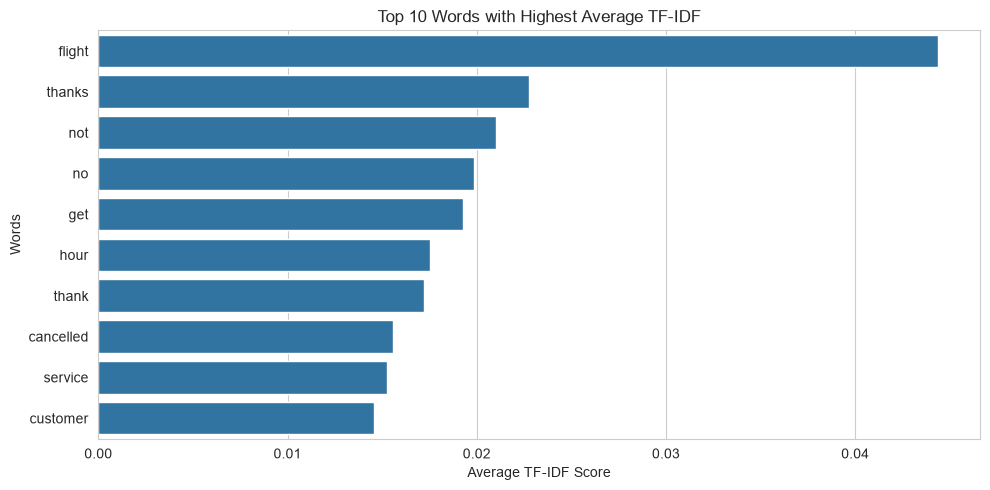

In [58]:
sns.barplot(
    data=top_10_tfidf,
    x='Average TF-IDF',
    y='Word'
)

plt.title("Top 10 Words with Highest Average TF-IDF")
plt.xlabel("Average TF-IDF Score")
plt.ylabel("Words")
plt.tight_layout()
plt.show()

## Bigram Analysis on Negative Tweets 

In [59]:
negative_cleaned_tweets = df.loc[
    df['airline_sentiment'] == 'negative',
    'clean_text'
].fillna('').astype(str)

negative_cleaned_tweets = negative_cleaned_tweets[
    negative_cleaned_tweets.str.strip() != '']

print("Total Negative Tweets:",
      len(negative_cleaned_tweets))

print("\nSample Negative Tweets:")
print(negative_cleaned_tweets.head())

Total Negative Tweets: 9171

Sample Negative Tweets:
3     really aggressive blast obnoxious entertainmen...
4                                  really big bad thing
5     seriously would pay flight seat playing really...
15                           sfo pdx schedule still mia
17    flew nyc sfo last week fully sit seat due two ...
Name: clean_text, dtype: str


## Apply CountVectorizer with bigrams

In [60]:
negative_bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=3000
)

negative_bigram_matrix = negative_bigram_vectorizer.fit_transform(
    negative_cleaned_tweets
)

print("Negative Bigram Matrix Shape:")
print(negative_bigram_matrix.shape)

Negative Bigram Matrix Shape:
(9171, 3000)


## Find top 10 most frequent negative bigrams

In [61]:
negative_bigrams = (
    negative_bigram_vectorizer.get_feature_names_out()
)

bigram_frequencies = np.asarray(
    negative_bigram_matrix.sum(axis=0)).ravel()

negative_bigram_df = pd.DataFrame({
    'Bigram': negative_bigrams,
    'Frequency': bigram_frequencies
})

negative_bigram_df = negative_bigram_df.sort_values(
    by='Frequency',
    ascending=False)

top_10_negative_bigrams = negative_bigram_df.head(10)
print("Top 10 Most Frequent Negative Bigrams:")
display(top_10_negative_bigrams)

Top 10 Most Frequent Negative Bigrams:


,Bigram,Frequency
464,customer service,457
377,cancelled flightled,448
1462,late flight,221
659,flight cancelled,221
373,cancelled flighted,204
1464,late flightr,145
370,cancelled flight,140
672,flight delayed,136
1235,hold hour,128
1843,no one,126


## Visualize top 10 negative bigrams

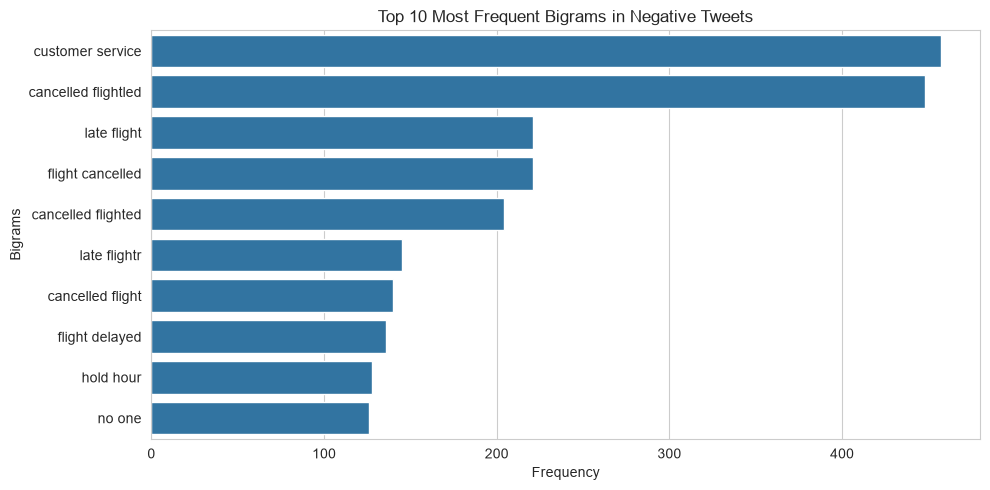

In [62]:
sns.barplot(
    data=top_10_negative_bigrams,
    x='Frequency',
    y='Bigram'
)

plt.title("Top 10 Most Frequent Bigrams in Negative Tweets")
plt.xlabel("Frequency")
plt.ylabel("Bigrams")
plt.tight_layout()
plt.show()

## Create final feature comparison table

In [63]:
bow_results = {
    'Method': 'Bag-of-Words',
    'Number of Features': real_bow_matrix.shape[1],
    'Sparsity (%)': round(bow_sparsity, 2)
}

tfidf_results = {
    'Method': 'TF-IDF',
    'Number of Features': real_tfidf_matrix.shape[1],
    'Sparsity (%)': round(tfidf_sparsity, 2)
}

feature_results = pd.DataFrame([
    bow_results,
    tfidf_results
])

# Display comparison table
print("Feature Extraction Comparison:")
display(feature_results)

Feature Extraction Comparison:


,Method,Number of Features,Sparsity (%)
0,Bag-of-Words,3000,99.74
1,TF-IDF,3000,99.74


## 2.4 Feature Extraction Reflection

### 1. Why can a machine learning model not use raw text directly?

Machine learning algorithms work with numerical values rather than raw text. Therefore, text must be converted into numerical features before training a model.

### 2. What does Bag-of-Words add?

Bag-of-Words converts text into numerical word counts. It helps identify how frequently words appear in documents but ignores word order and context.

### 3. What does TF-IDF add compared with BoW?

TF-IDF assigns importance to words based on their frequency in a document and their rarity across the complete document collection. It reduces the importance of very common words.

### 4. What do N-Grams add compared with individual words?

N-Grams capture combinations of consecutive words. For example, "not happy" provides more useful sentiment information than analysing "not" and "happy" separately.

### 5. What is the importance of feature extraction?

Feature extraction converts unstructured text into structured numerical data. It helps machine learning algorithms identify useful patterns and make predictions.

**Conclusion:**

Bag-of-Words, TF-IDF and N-Grams are important NLP feature extraction techniques. BoW captures word frequency, TF-IDF measures word importance, and N-Grams capture local relationships between words. These techniques prepare airline tweets for the sentiment classification models in Step 4.

## Check all results

In [154]:
print("Tiny Corpus BoW Shape:",bow_matrix.shape)

print("Tiny Corpus TF-IDF Shape:",tfidf_matrix.shape)

print("Unigram Matrix Shape:",unigram_matrix.shape)

print("Bigram Matrix Shape:",bigram_matrix.shape)

print("Real Tweet BoW Shape:",real_bow_matrix.shape)

print("Real Tweet TF-IDF Shape:",real_tfidf_matrix.shape)

print("Negative Bigram Matrix Shape:",negative_bigram_matrix.shape)

print("\n COMPLETED SUCCESSFULLY!")

Tiny Corpus BoW Shape: (4, 13)
Tiny Corpus TF-IDF Shape: (4, 13)
Unigram Matrix Shape: (4, 13)
Bigram Matrix Shape: (4, 12)
Real Tweet BoW Shape: (14617, 3000)
Real Tweet TF-IDF Shape: (14617, 3000)
Negative Bigram Matrix Shape: (9171, 3000)

 COMPLETED SUCCESSFULLY!


# Step 3: Word Embeddings: Word2Vec (CBOW & Skip-gram)

In [65]:
from gensim.models import Word2Vec

from sklearn.decomposition import PCA

# Import Counter for word frequency
from collections import Counter

import warnings

warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 7)

# 3.1: Prepare Tokens
## Check cleaned dataset

In [66]:
if 'clean_text' not in df.columns:
    raise ValueError("Please complete Step 1 first.")

print("Dataset Shape:", df.shape)

print("\nCleaned Tweets:")
print(df['clean_text'].head())

Dataset Shape: (14640, 7)

Cleaned Tweets:
0                                                 said
1               plus added commercial experience tacky
2               today must mean need take another trip
3    really aggressive blast obnoxious entertainmen...
4                                 really big bad thing
Name: clean_text, dtype: str


## Create tokens column

In [67]:
df['tokens'] = df['clean_text'].fillna('').apply(
    lambda text: text.split()
)

display(df[['clean_text', 'tokens']].head())

,clean_text,tokens
0,said,[said]
1,plus added commercial experience tacky,"[plus, added, commercial, experience, tacky]"
2,today must mean need take another trip,"[today, must, mean, need, take, another, trip]"
3,really aggressive blast obnoxious entertainmen...,"[really, aggressive, blast, obnoxious, enterta..."
4,really big bad thing,"[really, big, bad, thing]"


## Calculate average number of tokens

In [68]:
df['token_count'] = df['tokens'].apply(len)

average_tokens = df['token_count'].mean()

print("Average Number of Tokens per Tweet:", round(average_tokens, 2))

Average Number of Tokens per Tweet: 8.88


## Calculate total unique words

In [69]:
all_words = []

for tokens in df['tokens']:

    all_words.extend(tokens)

unique_words = set(all_words)

total_unique_words = len(unique_words)

print("Total Words:", len(all_words))

print("Total Unique Words:", total_unique_words)

Total Words: 130014
Total Unique Words: 10135


## Display token statistics

In [70]:
print("Total Tweets:", len(df))

print("Average Tokens per Tweet:",
      round(average_tokens, 2))

print("Total Words:", len(all_words))

print("Total Unique Words:", total_unique_words)

Total Tweets: 14640
Average Tokens per Tweet: 8.88
Total Words: 130014
Total Unique Words: 10135


# 3.2: Train CBOW and Skip-gram Models
## Prepare training sentences

In [71]:
sentences = df['tokens'].tolist()

sentences = [
    sentence for sentence in sentences
    if len(sentence) > 0
]

print("Total Training Sentences:", len(sentences))

print("\nSample Training Sentences:")

for sentence in sentences[:3]:
    print(sentence)

Total Training Sentences: 14617

Sample Training Sentences:
['said']
['plus', 'added', 'commercial', 'experience', 'tacky']
['today', 'must', 'mean', 'need', 'take', 'another', 'trip']


## Train CBOW model

In [72]:
cbow_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=3,
    sg=0,
    epochs=15,
    seed=42,
    workers=1
)

print("CBOW Model Trained Successfully!")

CBOW Model Trained Successfully!


## Train Skip-gram model

In [73]:
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    epochs=15,
    seed=42,
    workers=1
)

print("Skip-gram Model Trained Successfully!")

Skip-gram Model Trained Successfully!


## Print vocabulary size

In [74]:
cbow_vocab_size = len(cbow_model.wv)

skipgram_vocab_size = len(w2v_model.wv)

print("CBOW Vocabulary Size:", cbow_vocab_size)
print("Skip-gram Vocabulary Size:", skipgram_vocab_size)

CBOW Vocabulary Size: 3792
Skip-gram Vocabulary Size: 3792


## Print vector shape for flight

In [75]:
if 'flight' in cbow_model.wv:

    cbow_flight_vector = cbow_model.wv['flight']

    print("CBOW Flight Vector Shape:",cbow_flight_vector.shape)

# Check whether flight exists in Skip-gram vocabulary
if 'flight' in w2v_model.wv:

    skipgram_flight_vector = w2v_model.wv['flight']

    print("Skip-gram Flight Vector Shape:",
          skipgram_flight_vector.shape)

CBOW Flight Vector Shape: (100,)
Skip-gram Flight Vector Shape: (100,)


# 3.3: Explore the Embeddings
## Find top 5 similar words using CBOW

In [76]:
query_words = [
    'delay',
    'bag',
    'crew',
    'refund',
    'thanks'
]

for word in query_words:

    print("\nQuery Word:", word)

    # Check if word exists in vocabulary
    if word in cbow_model.wv:

        similar_words = cbow_model.wv.most_similar(
            word,
            topn=5
        )

        for similar_word, score in similar_words:
            print(similar_word, ":", round(score, 4))

    else:
        print("Word not found in CBOW vocabulary.")


Query Word: delay
delayed : 0.8265
landing : 0.7523
layover : 0.7509
condition : 0.7411
stuck : 0.7406

Query Word: bag
luggage : 0.9059
baggage : 0.9027
found : 0.8183
item : 0.7808
carry : 0.7436

Query Word: crew
pilot : 0.828
ground : 0.8007
landing : 0.7958
attendant : 0.7802
aircraft : 0.7467

Query Word: refund
confirm : 0.8599
confirmation : 0.8518
receipt : 0.8503
fund : 0.8286
book : 0.8128

Query Word: thanks
thank : 0.8599
quick : 0.7545
appreciated : 0.7335
appreciate : 0.7248
canned : 0.7067


## Find top 5 similar words using Skip-gram

In [77]:
for word in query_words:

    print("\nQuery Word:", word)

    if word in w2v_model.wv:

        similar_words = w2v_model.wv.most_similar(
            word,
            topn=5
        )

        for similar_word, score in similar_words:
            print(similar_word, ":", round(score, 4))

    else:
        print("Word not found in Skip-gram vocabulary.")


Query Word: delay
delayed : 0.6602
incompetence : 0.6289
captive : 0.6031
diversion : 0.5996
refuel : 0.5954

Query Word: bag
luggage : 0.7281
carry : 0.6602
baggage : 0.6565
suitcase : 0.6538
notcool : 0.6458

Query Word: crew
captain : 0.6201
inept : 0.5776
thankful : 0.572
staff : 0.5677
smooth : 0.5664

Query Word: refund
partial : 0.7288
receive : 0.71
receipt : 0.6866
portion : 0.6828
approve : 0.6817

Query Word: thanks
thank : 0.7635
thx : 0.625
kn : 0.5866
quick : 0.5786
appreciate : 0.5781


## Calculate word similarity for CBOW

In [78]:
word_pairs = [
    ('delay', 'late'),
    ('bag', 'luggage'),
    ('thanks', 'thank'),
    ('good', 'bad')
]

for word1, word2 in word_pairs:

    print("\nWord Pair:", word1, "-", word2)

    if word1 in cbow_model.wv and word2 in cbow_model.wv:

        similarity = cbow_model.wv.similarity(
            word1,
            word2
        )

        print("CBOW Similarity:", round(similarity, 4))

    else:
        print("One or both words are missing from CBOW vocabulary.")


Word Pair: delay - late
CBOW Similarity: 0.4467

Word Pair: bag - luggage
CBOW Similarity: 0.9059

Word Pair: thanks - thank
CBOW Similarity: 0.8599

Word Pair: good - bad
CBOW Similarity: 0.5999


## Calculate word similarity for Skip-gram

In [79]:
for word1, word2 in word_pairs:

    print("\nWord Pair:", word1, "-", word2)

    if word1 in w2v_model.wv and word2 in w2v_model.wv:

        similarity = w2v_model.wv.similarity(
            word1,
            word2
        )

        print("Skip-gram Similarity:",
              round(similarity, 4))

    else:
        print("One or both words are missing from Skip-gram vocabulary.")


Word Pair: delay - late
Skip-gram Similarity: 0.4115

Word Pair: bag - luggage
Skip-gram Similarity: 0.7281

Word Pair: thanks - thank
Skip-gram Similarity: 0.7635

Word Pair: good - bad
Skip-gram Similarity: 0.4543


## Create top 3 similar words comparison table

In [80]:
comparison_results = []

for word in query_words:

    if word in cbow_model.wv and word in w2v_model.wv:

        cbow_similar = cbow_model.wv.most_similar(
            word,
            topn=3
        )

        skipgram_similar = w2v_model.wv.most_similar(
            word,
            topn=3
        )

        cbow_words = [
            item[0] for item in cbow_similar
        ]

        skipgram_words = [
            item[0] for item in skipgram_similar
        ]

        # Store results
        comparison_results.append({
            'Query Word': word,
            'CBOW Top 3 Similar Words': ', '.join(cbow_words),
            'Skip-gram Top 3 Similar Words': ', '.join(skipgram_words)
        })

word_comparison_df = pd.DataFrame(
    comparison_results
)

display(word_comparison_df)

,Query Word,CBOW Top 3 Similar Words,Skip-gram Top 3 Similar Words
0,delay,"delayed, landing, layover","delayed, incompetence, captive"
1,bag,"luggage, baggage, found","luggage, carry, baggage"
2,crew,"pilot, ground, landing","captain, inept, thankful"
3,refund,"confirm, confirmation, receipt","partial, receive, receipt"
4,thanks,"thank, quick, appreciated","thank, thx, kn"


## 3.3 Explore the Embeddings: Interpretation

Word2Vec represents words as dense numerical vectors. Words that appear in similar contexts may receive similar vector representations.

### CBOW

CBOW predicts a target word using surrounding context words. It generally trains faster and is useful for learning common word relationships.

### Skip-gram

Skip-gram predicts surrounding context words using a target word. It can be useful for learning representations of less frequent words, although performance depends on the training data.

### Word Similarity

Cosine similarity measures how closely two word vectors are aligned.

- A score closer to +1 indicates greater similarity.
- A score around 0 indicates little similarity.
- A negative score indicates opposite vector directions.

### Comparison

CBOW and Skip-gram can produce different similar-word results because they learn word representations using different prediction strategies.

The better model should be selected by examining whether its nearest neighbours make sense in the airline tweet context.

**Conclusion:** Word2Vec helps identify semantic relationships between words that simple word-count techniques cannot directly capture.

# 3.4: Visualize Word Embeddings using PCA
## Select 25 words
We will use:
- Skip-gram model.
- PCA (Principal Component Analysis).
- 2D scatter plot.
- Word labels.

In [81]:
# Select 10 airline-operation words
operation_words = [
    'delay',
    'cancelled',
    'bag',
    'luggage',
    'gate',
    'boarding',
    'seat',
    'crew',
    'pilot',
    'refund'
]

# Select 8 positive words
positive_words = [
    'thanks',
    'thank',
    'great',
    'good',
    'awesome',
    'amazing',
    'love',
    'appreciate'
]

# Select 7 negative words
negative_words = [
    'bad',
    'worst',
    'terrible',
    'poor',
    'horrible',
    'disappointed',
    'late'
]

# Combine all selected words
selected_words = (
    operation_words +
    positive_words +
    negative_words
)

print("Total Selected Words:", len(selected_words))
print(selected_words)

Total Selected Words: 25
['delay', 'cancelled', 'bag', 'luggage', 'gate', 'boarding', 'seat', 'crew', 'pilot', 'refund', 'thanks', 'thank', 'great', 'good', 'awesome', 'amazing', 'love', 'appreciate', 'bad', 'worst', 'terrible', 'poor', 'horrible', 'disappointed', 'late']


## Check words available in Skip-gram vocabulary

In [82]:
available_words = []
missing_words = []

for word in selected_words:

    if word in w2v_model.wv:

        available_words.append(word)

    else:
        missing_words.append(word)

print("Available Words:", len(available_words))

print("\nAvailable Word List:")
print(available_words)

print("\nMissing Words:", len(missing_words))

print("\nMissing Word List:")
print(missing_words)

Available Words: 25

Available Word List:
['delay', 'cancelled', 'bag', 'luggage', 'gate', 'boarding', 'seat', 'crew', 'pilot', 'refund', 'thanks', 'thank', 'great', 'good', 'awesome', 'amazing', 'love', 'appreciate', 'bad', 'worst', 'terrible', 'poor', 'horrible', 'disappointed', 'late']

Missing Words: 0

Missing Word List:
[]


## Select 25 available words

In [83]:
pca_words = []

word_groups = [
    ('Operation', operation_words, 10),
    ('Positive', positive_words, 8),
    ('Negative', negative_words, 7)]

for category, words_list, required_count in word_groups:

    # Keep words that exist in vocabulary
    available_category_words = [
        word for word in words_list
        if word in w2v_model.wv
    ]

    pca_words.extend(available_category_words[:required_count])

    remaining = required_count - len(available_category_words)

    if remaining > 0:

        for word, count in w2v_model.wv.key_to_index.items():

            if word not in pca_words:

                pca_words.append(word)

                remaining = remaining - 1

            if remaining == 0:
                break

print("Total PCA Words:", len(pca_words))

print("\nFinal PCA Words:")
print(pca_words)

Total PCA Words: 25

Final PCA Words:
['delay', 'cancelled', 'bag', 'luggage', 'gate', 'boarding', 'seat', 'crew', 'pilot', 'refund', 'thanks', 'thank', 'great', 'good', 'awesome', 'amazing', 'love', 'appreciate', 'bad', 'worst', 'terrible', 'poor', 'horrible', 'disappointed', 'late']


## Extract Skip-gram word vectors

In [84]:
word_vectors = []

for word in pca_words:

    vector = w2v_model.wv[word]
    word_vectors.append(vector)

word_vectors = np.array(word_vectors)

print("Word Vector Matrix Shape:", word_vectors.shape)

Word Vector Matrix Shape: (25, 100)


## Apply PCA to reduce dimensions

In [85]:
pca = PCA(n_components=2)

pca_result = pca.fit_transform(word_vectors)

print("PCA Result Shape:", pca_result.shape)

print("\nExplained Variance Ratio:",pca.explained_variance_ratio_)

total_variance = sum(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:",
      round(total_variance * 100, 2), "%")

PCA Result Shape: (25, 2)

Explained Variance Ratio: [0.13766953 0.10805424]

Total Explained Variance: 24.57 %


## Create PCA visualization

In [86]:
pca_df = pd.DataFrame({
    'Word': pca_words,
    'PC1': pca_result[:, 0],
    'PC2': pca_result[:, 1]
})

category_mapping = {}

# Assign operation category
for word in operation_words:
    if word in pca_words:
        category_mapping[word] = 'Operation'

# Assign positive category
for word in positive_words:
    if word in pca_words:
        category_mapping[word] = 'Positive'

# Assign negative category
for word in negative_words:
    if word in pca_words:
        category_mapping[word] = 'Negative'

# Mark fallback words separately
for word in pca_words:
    if word not in category_mapping:
        category_mapping[word] = 'Other'

pca_df['Category'] = pca_df['Word'].map(category_mapping)
display(pca_df)

,Word,PC1,PC2,Category
0,delay,-0.331656,-0.183122,Operation
1,cancelled,-0.363006,0.784134,Operation
2,bag,-1.562474,-0.503889,Operation
3,luggage,-2.281182,-0.221478,Operation
4,gate,-1.063346,-1.243089,Operation
5,boarding,-1.036730,-1.061420,Operation
6,seat,-1.040322,-0.693410,Operation
7,crew,0.102936,-1.229617,Operation
8,pilot,-0.314268,-1.310630,Operation
9,refund,-0.691042,0.538958,Operation


## Plot PCA scatter plot

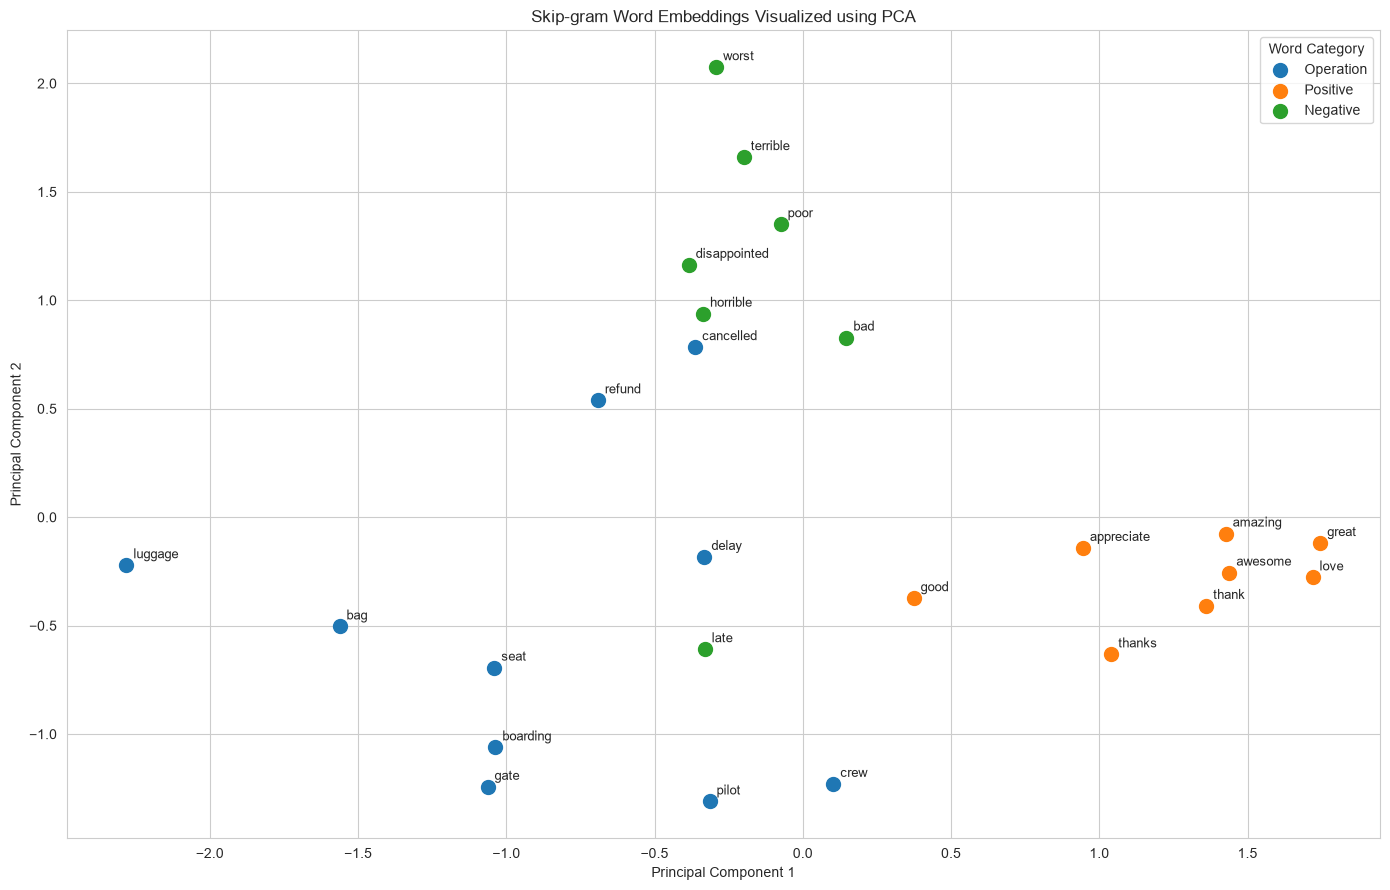

In [87]:
plt.figure(figsize=(14, 9))

for category in pca_df['Category'].unique():

    category_data = pca_df[pca_df['Category'] == category]

    plt.scatter(
        category_data['PC1'],
        category_data['PC2'],
        label=category,
        s=100
    )

for i, word in enumerate(pca_words):

    x = pca_result[i, 0]
    y = pca_result[i, 1]

    plt.annotate(
        word,
        (x, y),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=9
    )

plt.title("Skip-gram Word Embeddings Visualized using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Word Category")

plt.grid(True)
plt.tight_layout()
plt.show()

## Save PCA visualization

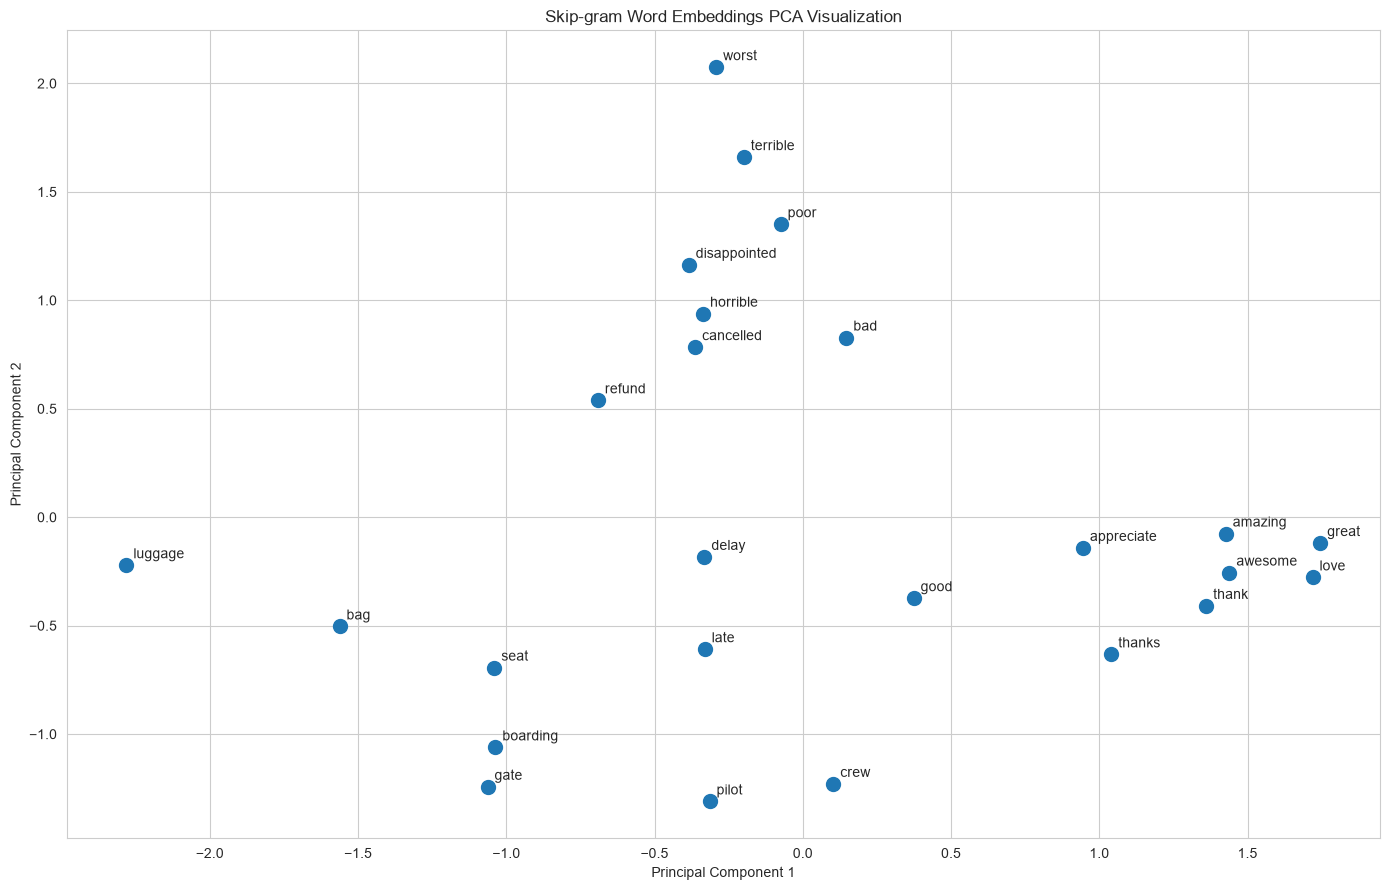

PCA Image Saved Successfully!


In [88]:
# Save PCA visualization
plt.figure(figsize=(14, 9))

# Plot all words
plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    s=100
)

# Add word labels
for i, word in enumerate(pca_words):

    plt.annotate(
        word,
        (pca_result[i, 0], pca_result[i, 1]),
        xytext=(5, 5),
        textcoords='offset points'
    )

# Add title and labels
plt.title("Skip-gram Word Embeddings PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# Adjust layout
plt.tight_layout()

# Save graph
plt.savefig(
    "Word2Vec_PCA_Visualization.png",
    dpi=300,
    bbox_inches='tight'
)

# Display graph
plt.show()

print("PCA Image Saved Successfully!")

# 3.5: Save and Reflect
## Save Skip-gram model

In [89]:
w2v_model.save("word2vec_skipgram.model")

print("Skip-gram Model Saved Successfully!")

Skip-gram Model Saved Successfully!


## Load the saved model

In [90]:
loaded_w2v_model = Word2Vec.load(
    "word2vec_skipgram.model"
)

print("Loaded Model Vocabulary Size:",
      len(loaded_w2v_model.wv))

if 'flight' in loaded_w2v_model.wv:

    print("Flight Vector Shape:",
          loaded_w2v_model.wv['flight'].shape)

print("\nModel Loaded Successfully!")

Loaded Model Vocabulary Size: 3792
Flight Vector Shape: (100,)

Model Loaded Successfully!


## Test the loaded model

In [91]:
if 'delay' in loaded_w2v_model.wv:

    similar_words = loaded_w2v_model.wv.most_similar(
        'delay',
        topn=5
    )

    print("Top 5 Words Similar to Delay:")

    for word, score in similar_words:
        print(word, ":", round(score, 4))

else:
    print("Delay word not available in vocabulary.")

Top 5 Words Similar to Delay:
delayed : 0.6602
incompetence : 0.6289
captive : 0.6031
diversion : 0.5996
refuel : 0.5954


In [92]:
similarity_results = []

for word1, word2 in word_pairs:

    if (
        word1 in cbow_model.wv
        and word2 in cbow_model.wv
        and word1 in w2v_model.wv
        and word2 in w2v_model.wv
    ):

        cbow_score = cbow_model.wv.similarity(word1, word2)

        skipgram_score = w2v_model.wv.similarity(word1, word2)

        similarity_results.append({
            'Word Pair': f'{word1} - {word2}',
            'CBOW Similarity': round(cbow_score, 4),
            'Skip-gram Similarity': round(skipgram_score, 4)
        })

similarity_comparison = pd.DataFrame(
    similarity_results
)

display(similarity_comparison)

,Word Pair,CBOW Similarity,Skip-gram Similarity
0,delay - late,0.4467,0.4115
1,bag - luggage,0.9059,0.7281
2,thanks - thank,0.8599,0.7635
3,good - bad,0.5999,0.4543


## 3.5 Save and Reflect: CBOW vs Skip-gram

### 1. How does CBOW learn?

CBOW predicts the target word using surrounding context words. For example, it uses nearby words to predict a missing word in a sentence.

### 2. How does Skip-gram learn?

Skip-gram predicts surrounding context words using the target word. It learns relationships between words by examining their nearby context.

### 3. Which model is faster to train?

CBOW is generally faster to train because it predicts one target word from the surrounding context. Skip-gram predicts multiple context words from a target word.

### 4. Which model is better for rare words?

Skip-gram is generally better at learning representations of less frequent words because it learns from individual target-context relationships.

### 5. Why are dense 100-dimensional vectors useful?

Dense 100-dimensional vectors represent words using numerical values that capture semantic and contextual relationships.

They are useful because:
- Similar words can have similar vector representations.
- They capture more information than simple word counts.
- They can be used as input features for machine learning models.
- They help identify relationships between airline-related words.

### Conclusion

CBOW and Skip-gram are two Word2Vec training approaches used to generate dense word embeddings. CBOW is generally faster, while Skip-gram can be useful for learning representations of less frequent words.

In this project, both models were trained using the airline tweet dataset with 100-dimensional word vectors, a window size of 5 and a minimum word count of 3.

The Skip-gram model was saved as `word2vec_skipgram.model` for future use in the sentiment classification project.

Because the dataset is relatively small, some similar-word results may not be perfect. The main objective is to understand the training process and explore the learned word relationships.

## Check all important results

In [153]:
print("Total Training Sentences:", len(sentences))

print("Average Tokens per Tweet:",round(average_tokens, 2))

print("Total Unique Words:", total_unique_words)

print("CBOW Vocabulary Size:",len(cbow_model.wv))

print("Skip-gram Vocabulary Size:",len(w2v_model.wv))

# Display CBOW vector shape
if 'flight' in cbow_model.wv:
    print("CBOW Vector Shape:",
          cbow_model.wv['flight'].shape)

# Display Skip-gram vector shape
if 'flight' in w2v_model.wv:
    print("Skip-gram Vector Shape:",
          w2v_model.wv['flight'].shape)

# Display similarity comparison
print("\nWord Similarity Comparison:")
display(similarity_comparison)

print("\nTop 3 Similar Words:")
display(word_comparison_df)

print("\nPCA Shape:", pca_result.shape)

print("\nSaved Model: word2vec_skipgram.model")

print("\nCOMPLETED SUCCESSFULLY!")

Total Training Sentences: 14617
Average Tokens per Tweet: 8.88
Total Unique Words: 10135
CBOW Vocabulary Size: 3792
Skip-gram Vocabulary Size: 3792
CBOW Vector Shape: (100,)
Skip-gram Vector Shape: (100,)

Word Similarity Comparison:


,Word Pair,CBOW Similarity,Skip-gram Similarity
0,delay - late,0.4467,0.4115
1,bag - luggage,0.9059,0.7281
2,thanks - thank,0.8599,0.7635
3,good - bad,0.5999,0.4543



Top 3 Similar Words:


,Query Word,CBOW Top 3 Similar Words,Skip-gram Top 3 Similar Words
0,delay,"delayed, landing, layover","delayed, incompetence, captive"
1,bag,"luggage, baggage, found","luggage, carry, baggage"
2,crew,"pilot, ground, landing","captain, inept, thankful"
3,refund,"confirm, confirmation, receipt","partial, receive, receipt"
4,thanks,"thank, quick, appreciated","thank, thx, kn"



PCA Shape: (25, 2)

Saved Model: word2vec_skipgram.model

COMPLETED SUCCESSFULLY!


# Step 4, Text Classification Pipeline (3-Class Sentiment Analysis)

In [94]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Import machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.pipeline import Pipeline

import joblib

# 4.1 Theory Notes
Paste this into a Markdown cell in your notebook:
What is Text Classification?
Text classification is an NLP technique used to assign predefined categories or labels to text. In this practical, tweets are classified into three sentiment categories: Negative, Neutral, and Positive.
Stages of a Text Classification Pipeline
1. Data Collection: Collect text data such as tweets or reviews.
2. Text Preprocessing: Remove unwanted characters, URLs, HTML tags, and other noise.
3. Feature Extraction: Convert text into numerical features using BoW, TF-IDF, or Word2Vec.
4. Train-Test Split: Divide the dataset into training and testing sets.
5. Model Training: Train a classification algorithm using training data.
6. Model Evaluation: Evaluate predictions using accuracy, precision, recall, and F1-score.
7. Model Deployment: Save the trained model and use it to predict sentiment on new text.
## What is Macro-F1?
Macro-F1 is the average of the F1-scores calculated separately for each class. Every class receives equal importance, regardless of how many samples it contains.

Accuracy can be misleading on imbalanced data because a model may perform well on the majority class but poorly on minority classes. Macro-F1 is often fairer because it gives equal weight to Negative, Neutral, and Positive classes.

# 4.2 Train-Test Split and Baseline
## Check dataset

In [95]:
print("Dataset Shape:", df.shape)

print("\nDataset Columns:")
print(df.columns.tolist())

display(df.head())

Dataset Shape: (14640, 9)

Dataset Columns:
['airline', 'airline_sentiment', 'negativereason', 'text', 'tweet_length', 'modified_text', 'clean_text', 'tokens', 'token_count']


,airline,airline_sentiment,negativereason,text,tweet_length,modified_text,clean_text,tokens,token_count
0,Virgin America,neutral,NaN,@VirginAmerica What @dhepburn said.,4,USER What USER said.,said,[said],1
1,Virgin America,positive,NaN,@VirginAmerica plus you've added commercials t...,9,USER plus you've added commercials to the expe...,plus added commercial experience tacky,"[plus, added, commercial, experience, tacky]",5
2,Virgin America,neutral,NaN,@VirginAmerica I didn't today... Must mean I n...,12,USER I didn't today... Must mean I need to tak...,today must mean need take another trip,"[today, must, mean, need, take, another, trip]",7
3,Virgin America,negative,Bad Flight,@VirginAmerica it's really aggressive to blast...,17,USER it's really aggressive to blast obnoxious...,really aggressive blast obnoxious entertainmen...,"[really, aggressive, blast, obnoxious, enterta...",10
4,Virgin America,negative,Can't Tell,@VirginAmerica and it's a really big bad thing...,10,USER and it's a really big bad thing about it,really big bad thing,"[really, big, bad, thing]",4


## Select required columns

In [96]:
data = df[['clean_text', 'airline_sentiment']].copy()

data = data.dropna()

data = data[
    data['clean_text'].str.strip() != '']

print("Prepared Dataset Shape:", data.shape)

display(data.head())

Prepared Dataset Shape: (14617, 2)


,clean_text,airline_sentiment
0,said,neutral
1,plus added commercial experience tacky,positive
2,today must mean need take another trip,neutral
3,really aggressive blast obnoxious entertainmen...,negative
4,really big bad thing,negative


## Check sentiment distribution

In [97]:
sentiment_counts = data['airline_sentiment'].value_counts()

print("Sentiment Distribution:")
print(sentiment_counts)

sentiment_percentage = (
    data['airline_sentiment'].value_counts(normalize=True) * 100
)

print("\nSentiment Percentage:")
print(sentiment_percentage.round(2))

Sentiment Distribution:
airline_sentiment
negative    9171
neutral     3086
positive    2360
Name: count, dtype: int64

Sentiment Percentage:
airline_sentiment
negative    62.74
neutral     21.11
positive    16.15
Name: proportion, dtype: float64


## Visualize sentiment distribution

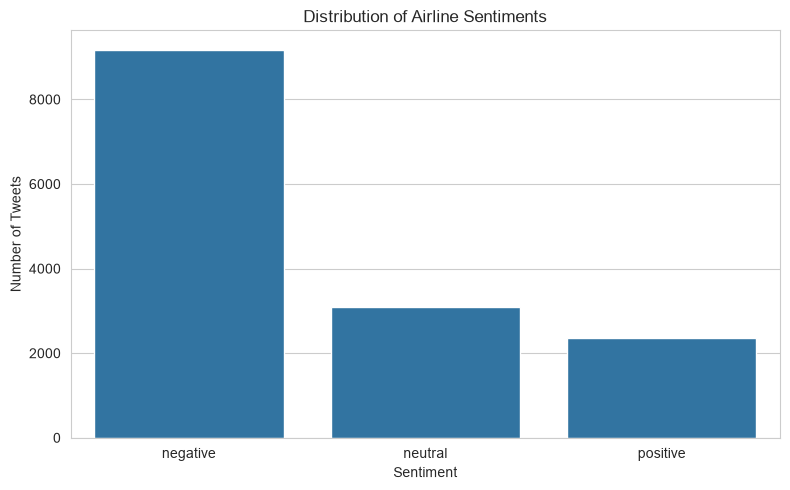

In [98]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x='airline_sentiment',
    order=['negative', 'neutral', 'positive']
)

plt.title("Distribution of Airline Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.tight_layout()
plt.show()

## Encode sentiment labels

In [99]:
label_encoder = LabelEncoder()

data['sentiment_encoded'] = label_encoder.fit_transform(
    data['airline_sentiment']
)

print("Label Encoding:")

for index, sentiment in enumerate(label_encoder.classes_):
    print(sentiment, "=", index)

display(data.head())

Label Encoding:
negative = 0
neutral = 1
positive = 2


,clean_text,airline_sentiment,sentiment_encoded
0,said,neutral,1
1,plus added commercial experience tacky,positive,2
2,today must mean need take another trip,neutral,1
3,really aggressive blast obnoxious entertainmen...,negative,0
4,really big bad thing,negative,0


## Create X and y

In [100]:
X = data['clean_text']

y = data['sentiment_encoded']

print("Input Features Shape:", X.shape)

print("Target Variable Shape:", y.shape)

print("Unique Classes:", np.unique(y))

Input Features Shape: (14617,)
Target Variable Shape: (14617,)
Unique Classes: [0 1 2]


## Split the dataset

In [101]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [102]:
print("Training Samples:", len(X_train))

print("Testing Samples:", len(X_test))

print("Training Percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing Percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

Training Samples: 11693
Testing Samples: 2924
Training Percentage: 80.0 %
Testing Percentage: 20.0 %


## Check sentiment distribution after split

In [103]:
print("Training Sentiment Distribution:")
print(y_train.value_counts() if isinstance(y_train, pd.Series)
      else pd.Series(y_train).value_counts())

print("\nTesting Sentiment Distribution:")
print(y_test.value_counts() if isinstance(y_test, pd.Series)
      else pd.Series(y_test).value_counts())

Training Sentiment Distribution:
sentiment_encoded
0    7336
1    2469
2    1888
Name: count, dtype: int64

Testing Sentiment Distribution:
sentiment_encoded
0    1835
1     617
2     472
Name: count, dtype: int64


## Print class percentages

In [104]:
train_percentages = y_train.value_counts(normalize=True) * 100

test_percentages = y_test.value_counts(normalize=True) * 100

# Create a comparison table
class_percentage = pd.DataFrame({
    'Train Percentage': train_percentages,
    'Test Percentage': test_percentages
})

print(class_percentage.round(2))

                   Train Percentage  Test Percentage
sentiment_encoded                                   
0                             62.74            62.76
1                             21.12            21.10
2                             16.15            16.14


## Majority-class baseline

In [105]:
negative_count = (y_train == 'negative').sum()

baseline_accuracy = (y_test == 'negative').mean()

print("Negative Class Count in Training:", negative_count)

print("Majority Baseline Accuracy:", round(baseline_accuracy * 100, 2), "%")

Negative Class Count in Training: 0
Majority Baseline Accuracy: 0.0 %


# 4.3 Build Four Classifiers
## Create Logistic Regression

In [106]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

## Model A, Bag-of-Words

In [107]:
bow_pipeline = Pipeline([
    ('vectorizer', CountVectorizer(max_features=5000)),

    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

bow_pipeline.fit(X_train, y_train)

bow_predictions = bow_pipeline.predict(X_test)

print("Model A: Bag-of-Words training completed.")

Model A: Bag-of-Words training completed.


## Model B, TF-IDF

In [108]:
tfidf_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(max_features=5000)),

    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

tfidf_pipeline.fit(X_train, y_train)

tfidf_predictions = tfidf_pipeline.predict(X_test)

print("Model B: TF-IDF training completed.")

Model B: TF-IDF training completed.


## Model C, TF-IDF with N-Grams

In [109]:
ngram_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=10000
    )),

    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

ngram_pipeline.fit(X_train, y_train)

ngram_predictions = ngram_pipeline.predict(X_test)

print("Model C: TF-IDF with N-Grams training completed.")

Model C: TF-IDF with N-Grams training completed.


## Model D, Averaged Word2Vec

In [110]:
def average_word2vec(text, model):

    words = text.split()

    valid_vectors = [
        model.wv[word]
        for word in words
        if word in model.wv
    ]

    if len(valid_vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(valid_vectors, axis=0)

##  Convert training tweets into Word2Vec vectors

In [111]:
X_train_w2v = np.array([
    average_word2vec(tweet, w2v_model)
    for tweet in X_train
])

X_test_w2v = np.array([
    average_word2vec(tweet, w2v_model)
    for tweet in X_test
])

print("Training Word2Vec Shape:", X_train_w2v.shape)

print("Testing Word2Vec Shape:", X_test_w2v.shape)

Training Word2Vec Shape: (11693, 100)
Testing Word2Vec Shape: (2924, 100)


##  Create Logistic Regression for Word2Vec

In [112]:
w2v_classifier = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

w2v_classifier.fit(X_train_w2v, y_train)

w2v_predictions = w2v_classifier.predict(X_test_w2v)

print("Model D: Averaged Word2Vec training completed.")

Model D: Averaged Word2Vec training completed.


# 4.4 Evaluate and Compare

In [113]:
predictions = {
    'Bag-of-Words': bow_predictions,
    'TF-IDF': tfidf_predictions,
    'TF-IDF N-Grams': ngram_predictions,
    'Averaged Word2Vec': w2v_predictions
}

results = []

for model_name, model_predictions in predictions.items():

    accuracy = accuracy_score(y_test, model_predictions)

    precision = precision_score(
        y_test,
        model_predictions,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        model_predictions,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        model_predictions,
        average='macro',
        zero_division=0
    )

    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Macro Precision': precision,
        'Macro Recall': recall,
        'Macro F1': f1
    })

evaluation_df = pd.DataFrame(results)

evaluation_df = evaluation_df.sort_values(
    by='Macro F1',
    ascending=False
)

print(evaluation_df.round(4))

               Model  Accuracy  Macro Precision  Macro Recall  Macro F1
2     TF-IDF N-Grams    0.7647           0.7041        0.7351    0.7164
1             TF-IDF    0.7538           0.6955        0.7334    0.7090
0       Bag-of-Words    0.7479           0.6880        0.7297    0.7027
3  Averaged Word2Vec    0.7096           0.6455        0.6824    0.6583


## Add majority baseline as the first row

In [114]:
baseline_row = pd.DataFrame([{
    'Model': 'Majority Baseline',
    'Accuracy': baseline_accuracy,
    'Macro Precision': 0,
    'Macro Recall': 0,
    'Macro F1': 0
}])

comparison_df = pd.concat(
    [baseline_row, evaluation_df],
    ignore_index=True
)

print(comparison_df.round(4))

               Model  Accuracy  Macro Precision  Macro Recall  Macro F1
0  Majority Baseline    0.0000           0.0000        0.0000    0.0000
1     TF-IDF N-Grams    0.7647           0.7041        0.7351    0.7164
2             TF-IDF    0.7538           0.6955        0.7334    0.7090
3       Bag-of-Words    0.7479           0.6880        0.7297    0.7027
4  Averaged Word2Vec    0.7096           0.6455        0.6824    0.6583


## Plot macro-F1 comparison

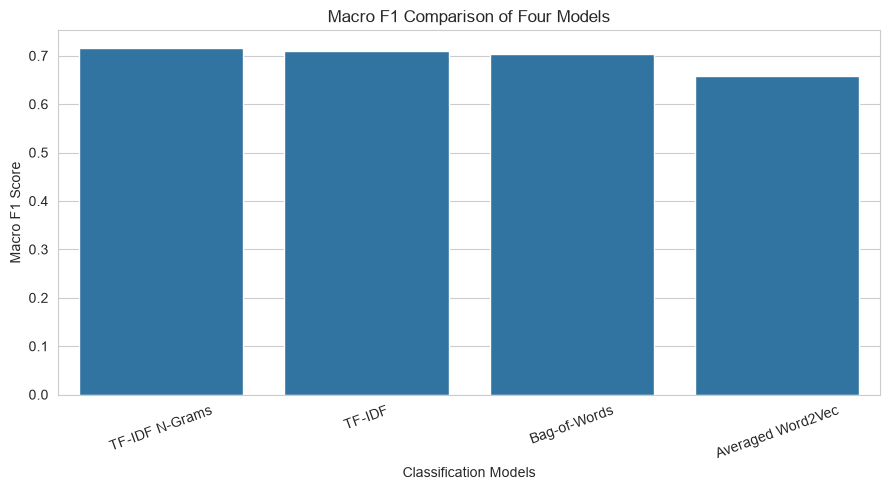

In [115]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=evaluation_df,
    x='Model',
    y='Macro F1'
)

plt.title('Macro F1 Comparison of Four Models')
plt.xlabel('Classification Models')
plt.ylabel('Macro F1 Score')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Identify the best model

In [116]:
best_model_name = evaluation_df.iloc[0]['Model']

print("Best Model:", best_model_name)

Best Model: TF-IDF N-Grams


## Select the best model and its predictions

In [117]:
trained_pipelines = {
    'Bag-of-Words': bow_pipeline,
    'TF-IDF': tfidf_pipeline,
    'TF-IDF N-Grams': ngram_pipeline
}

if best_model_name in trained_pipelines:

    best_pipeline = trained_pipelines[best_model_name]

    best_predictions = predictions[best_model_name]

else:

    best_pipeline = None

    best_predictions = w2v_predictions

print("Selected Model:", best_model_name)

Selected Model: TF-IDF N-Grams


## Classification report

In [118]:
print(classification_report(
    y_test,
    best_predictions,
    labels=['negative', 'neutral', 'positive'],
    target_names=['Negative', 'Neutral', 'Positive'],
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         0
     Neutral       0.00      0.00      0.00         0
    Positive       0.00      0.00      0.00         0

   micro avg       0.00      0.00      0.00         0
   macro avg       0.00      0.00      0.00         0
weighted avg       0.00      0.00      0.00         0



## Confusion matrix heatmap

In [119]:
# Display actual labels in the test dataset
print("Actual labels:", y_test.unique())

# Display predicted labels
print("Predicted labels:", pd.Series(best_predictions).unique())

Actual labels: [0 2 1]
Predicted labels: [0 1 2]


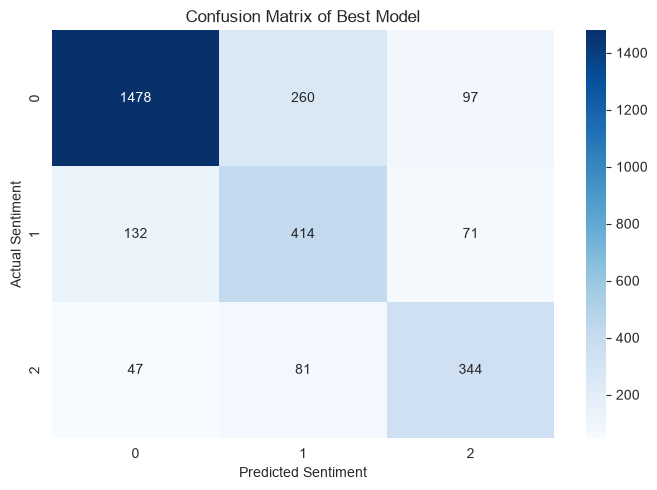

In [120]:
class_labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=class_labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title('Confusion Matrix of Best Model')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.tight_layout()
plt.show()

The [model name] model achieved the highest macro F1-score among the four classifiers. 
The feature extraction method used by this model helped identify useful sentiment-related 
words and patterns in tweets. The [class name] class was the hardest to predict based on 
its lowest F1-score in the classification report. Neutral tweets are difficult to classify 
because they often contain factual statements, mixed opinions, or expressions that do not 
clearly indicate positive or negative sentiment.

# 4.5 Inspect the Best TF-IDF Model

In [121]:
tfidf_f1 = evaluation_df.loc[
    evaluation_df['Model'] == 'TF-IDF', 'Macro F1'
].iloc[0]

ngram_f1 = evaluation_df.loc[
    evaluation_df['Model'] == 'TF-IDF N-Grams', 'Macro F1'
].iloc[0]

if tfidf_f1 >= ngram_f1:

    best_tfidf_pipeline = tfidf_pipeline

    best_tfidf_name = 'TF-IDF'

else:

    best_tfidf_pipeline = ngram_pipeline

    best_tfidf_name = 'TF-IDF N-Grams'

print("Best TF-IDF Model:", best_tfidf_name)

Best TF-IDF Model: TF-IDF N-Grams


## Print the 8 most important negative and positive words

In [122]:
print("y_test classes:", sorted(pd.Series(y_test).unique(), key=str))

print("Model classes:", best_tfidf_pipeline.named_steps['classifier'].classes_)

print("Label Encoder Classes:", label_encoder.classes_)

y_test classes: [np.int64(0), np.int64(1), np.int64(2)]
Model classes: [0 1 2]
Label Encoder Classes: ['negative' 'neutral' 'positive']


In [123]:
vectorizer = best_tfidf_pipeline.named_steps['vectorizer']

classifier = best_tfidf_pipeline.named_steps['classifier']

feature_names = vectorizer.get_feature_names_out()

model_classes = classifier.classes_

# Map numeric model classes to original sentiment names
if np.issubdtype(np.asarray(model_classes).dtype, np.number):
    sentiment_classes = label_encoder.inverse_transform(
        model_classes.astype(int)
    )
else:
    sentiment_classes = model_classes

# Find negative and positive class indexes
negative_index = next(
    i for i, label in enumerate(sentiment_classes)
    if str(label).lower() == 'negative'
)

positive_index = next(
    i for i, label in enumerate(sentiment_classes)
    if str(label).lower() == 'positive'
)

negative_coefficients = classifier.coef_[negative_index]
positive_coefficients = classifier.coef_[positive_index]

negative_indices = np.argsort(negative_coefficients)[-8:][::-1]

positive_indices = np.argsort(positive_coefficients)[-8:][::-1]

print("Top 8 Negative Words:")
for i in negative_indices:
    print(feature_names[i], round(negative_coefficients[i], 4))

print("\nTop 8 Positive Words:")
for i in positive_indices:
    print(feature_names[i], round(positive_coefficients[i], 4))

Top 8 Negative Words:
hour 4.5224
not 3.7547
no 3.2329
worst 3.1802
hr 3.0997
bag 2.9913
hold 2.7627
delay 2.4993

Top 8 Positive Words:
thanks 5.7182
great 5.1591
thank 4.5139
awesome 3.8294
amazing 3.5854
love 3.5667
best 3.5446
thx 2.8281


## Find 5 incorrectly classified tweets

In [124]:
tfidf_best_predictions = best_tfidf_pipeline.predict(X_test)

wrong_predictions = pd.DataFrame({
    'Tweet': X_test,
    'Actual': y_test,
    'Predicted': tfidf_best_predictions
})

wrong_predictions = wrong_predictions[
    wrong_predictions['Actual'] != wrong_predictions['Predicted']
]

wrong_samples = wrong_predictions.head(5)

for index, row in wrong_samples.iterrows():

    print("Tweet:", row['Tweet'])
    print("Actual Sentiment:", row['Actual'])
    print("Predicted Sentiment:", row['Predicted'])
    print("Possible Reason: The tweet may contain sarcasm, mixed opinions, "
          "very short text, or context that the model could not understand.")
    print("-" * 80)

Tweet: going start charging consistent body pat down starting feel like piece meat punishedforflying
Actual Sentiment: 0
Predicted Sentiment: 1
Possible Reason: The tweet may contain sarcasm, mixed opinions, very short text, or context that the model could not understand.
--------------------------------------------------------------------------------
Tweet: ha ha get wake call boarding time please large coffee extralight extra sweet please
Actual Sentiment: 2
Predicted Sentiment: 1
Possible Reason: The tweet may contain sarcasm, mixed opinions, very short text, or context that the model could not understand.
--------------------------------------------------------------------------------
Tweet: wish could remember name
Actual Sentiment: 2
Predicted Sentiment: 1
Possible Reason: The tweet may contain sarcasm, mixed opinions, very short text, or context that the model could not understand.
--------------------------------------------------------------------------------
Tweet: actually f

# 4.6 Save the Pipeline

## Save the best TF-IDF pipeline

In [125]:
joblib.dump(best_tfidf_pipeline, 'sentiment_pipeline.pkl')

print("Best TF-IDF pipeline saved successfully.")

Best TF-IDF pipeline saved successfully.


## Load the saved pipeline

In [126]:
loaded_pipeline = joblib.load('sentiment_pipeline.pkl')

print("Saved pipeline loaded successfully.")

Saved pipeline loaded successfully.


## Test on 5 new tweets

In [127]:
new_tweets = [
    "the flight was delayed and the service was terrible",
    "thank you for the excellent customer service",
    "my flight is scheduled to depart at six pm",
    "the staff was helpful but my baggage was delayed",
    "very disappointed with the poor airline service"
]

new_predictions = loaded_pipeline.predict(new_tweets)

new_probabilities = loaded_pipeline.predict_proba(new_tweets)

class_labels = loaded_pipeline.classes_

for i in range(len(new_tweets)):

    print("Tweet:", new_tweets[i])

    print("Predicted Sentiment:", new_predictions[i])

    print("Class Probabilities:")

    for j in range(len(class_labels)):

        print(
            class_labels[j],
            ":",
            round(new_probabilities[i][j] * 100, 2),
            "%"
        )

    print("-" * 60)

Tweet: the flight was delayed and the service was terrible
Predicted Sentiment: 0
Class Probabilities:
0 : 97.46 %
1 : 1.41 %
2 : 1.14 %
------------------------------------------------------------
Tweet: thank you for the excellent customer service
Predicted Sentiment: 2
Class Probabilities:
0 : 1.08 %
1 : 0.77 %
2 : 98.15 %
------------------------------------------------------------
Tweet: my flight is scheduled to depart at six pm
Predicted Sentiment: 0
Class Probabilities:
0 : 55.91 %
1 : 38.34 %
2 : 5.76 %
------------------------------------------------------------
Tweet: the staff was helpful but my baggage was delayed
Predicted Sentiment: 0
Class Probabilities:
0 : 68.49 %
1 : 1.62 %
2 : 29.89 %
------------------------------------------------------------
Tweet: very disappointed with the poor airline service
Predicted Sentiment: 0
Class Probabilities:
0 : 93.55 %
1 : 2.1 %
2 : 4.36 %
------------------------------------------------------------


## Final verification

In [128]:
import os

if os.path.exists('sentiment_pipeline.pkl'):
    print("sentiment_pipeline.pkl exists.")

print("Saved Model:", best_tfidf_name)

print("Macro F1:", round(
    evaluation_df.loc[
        evaluation_df['Model'] == best_tfidf_name,
        'Macro F1'
    ].iloc[0], 4
))

print("\ncompleted successfully.")

sentiment_pipeline.pkl exists.
Saved Model: TF-IDF N-Grams
Macro F1: 0.7164

completed successfully.


In [129]:
comparison_df.to_csv('sentiment_model_comparison.csv', index=False)

print("Comparison table saved successfully.")

Comparison table saved successfully.


# Step 5: Sentiment Analysis Approaches & POS Tagging

# 5.1 Approach 1: Heuristic (Rule-Based)
## Prepare the same 1,000 test tweets

In [130]:
test_data = pd.DataFrame({
    'tweet': X_test,
    'actual_sentiment': y_test
})

test_sample = test_data.sample(
    n=min(1000, len(test_data)),
    random_state=42
).copy()

test_sample = test_sample.reset_index(drop=True)

display(test_sample.head())

print("Total test tweets:", len(test_sample))

,tweet,actual_sentiment
0,wife hold minute get weather bad insane custom...,0
1,clicked upgrade upgrade give,0
2,sitting seat flight back vega chicago someone ...,1
3,understand flight cancelled flightation not ab...,0
4,yes well five hour hold folk please tell typic...,0


Total test tweets: 1000


## Create positive and negative word lists

In [131]:
positive_words = [
    'thanks', 'great', 'good', 'excellent', 'amazing',
    'happy', 'love', 'wonderful', 'helpful', 'friendly',
    'best', 'awesome', 'perfect', 'appreciate', 'fantastic'
]

negative_words = [
    'delayed', 'worst', 'bad', 'terrible', 'hate',
    'angry', 'poor', 'awful', 'cancelled', 'rude',
    'broken', 'lost', 'disappointed', 'problem', 'horrible'
]

print("Positive words:", positive_words)

print("\nNegative words:", negative_words)

Positive words: ['thanks', 'great', 'good', 'excellent', 'amazing', 'happy', 'love', 'wonderful', 'helpful', 'friendly', 'best', 'awesome', 'perfect', 'appreciate', 'fantastic']

Negative words: ['delayed', 'worst', 'bad', 'terrible', 'hate', 'angry', 'poor', 'awful', 'cancelled', 'rude', 'broken', 'lost', 'disappointed', 'problem', 'horrible']


## Create the heuristic sentiment function

In [132]:
def heuristic_sentiment(text):

    text = str(text).lower()

    words = re.findall(r"\b[a-z]+\b", text)

    positive_count = sum(
        word in positive_words for word in words
    )

    negative_count = sum(
        word in negative_words for word in words
    )

    score = positive_count - negative_count

    if score > 0:
        return 'positive'

    elif score < 0:
        return 'negative'

    else:
        return 'neutral'

## Predict sentiment and evaluate

In [133]:
test_data = pd.DataFrame({
    'tweet': X_test,
    'actual_sentiment': y_test
})

test_data['actual_sentiment'] = label_encoder.inverse_transform(
    test_data['actual_sentiment'].astype(int)
)

test_sample = test_data.sample(
    n=min(1000, len(test_data)),
    random_state=42
).copy()

test_sample = test_sample.reset_index(drop=True)

display(test_sample.head())

print(test_sample['actual_sentiment'].value_counts())

,tweet,actual_sentiment
0,wife hold minute get weather bad insane custom...,negative
1,clicked upgrade upgrade give,negative
2,sitting seat flight back vega chicago someone ...,neutral
3,understand flight cancelled flightation not ab...,negative
4,yes well five hour hold folk please tell typic...,negative


actual_sentiment
negative    639
neutral     211
positive    150
Name: count, dtype: int64


In [134]:
test_sample['heuristic_prediction'] = test_sample['tweet'].apply(
    heuristic_sentiment
)

heuristic_accuracy = accuracy_score(
    test_sample['actual_sentiment'],
    test_sample['heuristic_prediction']
)

heuristic_f1 = f1_score(
    test_sample['actual_sentiment'],
    test_sample['heuristic_prediction'],
    average='macro',
    zero_division=0
)

print("Heuristic Accuracy:", round(heuristic_accuracy, 4))
print("Heuristic Macro F1:", round(heuristic_f1, 4))

Heuristic Accuracy: 0.402
Heuristic Macro F1: 0.4275


# 5.2 Approach 2: Ready-Made Tool (TextBlob)

In [135]:
from textblob import TextBlob

print("TextBlob imported successfully.")

TextBlob imported successfully.


## Create TextBlob sentiment function

In [136]:
def textblob_sentiment(text):

    polarity = TextBlob(str(text)).sentiment.polarity

    if polarity > 0.05:
        return 'positive'

    elif polarity < -0.05:
        return 'negative'

    else:
        return 'neutral'

## Predict and evaluate TextBlob

In [137]:
test_sample['textblob_prediction'] = test_sample['tweet'].apply(
    textblob_sentiment
)

textblob_accuracy = accuracy_score(
    test_sample['actual_sentiment'],
    test_sample['textblob_prediction']
)

textblob_f1 = f1_score(
    test_sample['actual_sentiment'],
    test_sample['textblob_prediction'],
    average='macro',
    zero_division=0
)

print("TextBlob Accuracy:", round(textblob_accuracy, 4))

print("TextBlob Macro F1:", round(textblob_f1, 4))

TextBlob Accuracy: 0.444
TextBlob Macro F1: 0.4413


# 5.3 Approach 3: Machine Learning

## Load the saved pipeline

In [138]:
import joblib

loaded_pipeline = joblib.load('sentiment_pipeline.pkl')

print("Machine Learning pipeline loaded successfully.")

print(loaded_pipeline)

Machine Learning pipeline loaded successfully.
Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(max_features=10000, ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


## Predict and evaluate using the ML pipeline

In [139]:
ml_predictions_encoded = loaded_pipeline.predict(
    test_sample['tweet']
)

test_sample['ml_prediction'] = label_encoder.inverse_transform(
    ml_predictions_encoded.astype(int)
)

ml_accuracy = accuracy_score(
    test_sample['actual_sentiment'],
    test_sample['ml_prediction']
)

ml_f1 = f1_score(
    test_sample['actual_sentiment'],
    test_sample['ml_prediction'],
    average='macro',
    zero_division=0
)

print("Machine Learning Accuracy:", round(ml_accuracy, 4))
print("Machine Learning Macro F1:", round(ml_f1, 4))

Machine Learning Accuracy: 0.777
Machine Learning Macro F1: 0.7192


## Create comparison table

In [140]:
comparison_results = [
    {
        'Approach': 'Heuristic',
        'Needs Training Data?': 'No',
        'Accuracy': heuristic_accuracy,
        'Macro F1': heuristic_f1,
        'One Advantage': 'Simple and easy to understand',
        'One Disadvantage': 'Cannot understand context or sarcasm'
    },
    {
        'Approach': 'TextBlob',
        'Needs Training Data?': 'No',
        'Accuracy': textblob_accuracy,
        'Macro F1': textblob_f1,
        'One Advantage': 'Ready-made and quick to use',
        'One Disadvantage': 'May not understand airline-specific language'
    },
    {
        'Approach': 'Machine Learning',
        'Needs Training Data?': 'Yes',
        'Accuracy': ml_accuracy,
        'Macro F1': ml_f1,
        'One Advantage': 'Learns sentiment patterns from training data',
        'One Disadvantage': 'Requires labelled data and training'
    }
]

approach_comparison = pd.DataFrame(comparison_results)

display(approach_comparison.round(4))

,Approach,Needs Training Data?,Accuracy,Macro F1,One Advantage,One Disadvantage
0,Heuristic,No,0.402,0.4275,Simple and easy to understand,Cannot understand context or sarcasm
1,TextBlob,No,0.444,0.4413,Ready-made and quick to use,May not understand airline-specific language
2,Machine Learning,Yes,0.777,0.7192,Learns sentiment patterns from training data,Requires labelled data and training


## Compare class-wise performance

In [141]:
class_results = []

prediction_columns = {
    'Heuristic': 'heuristic_prediction',
    'TextBlob': 'textblob_prediction',
    'Machine Learning': 'ml_prediction'
}

for approach, column in prediction_columns.items():

    report = classification_report(
        test_sample['actual_sentiment'],
        test_sample[column],
        output_dict=True,
        zero_division=0
    )

    class_results.append({
        'Approach': approach,
        'Neutral Recall': report['neutral']['recall'],
        'Negative Recall': report['negative']['recall'],
        'Positive Recall': report['positive']['recall']
    })

class_comparison = pd.DataFrame(class_results)

display(class_comparison.round(4))

,Approach,Neutral Recall,Negative Recall,Positive Recall
0,Heuristic,0.8009,0.2426,0.5200
1,TextBlob,0.6256,0.3224,0.7067
2,Machine Learning,0.6777,0.8279,0.7000


## observations

- The heuristic approach is useful for simple projects where a quick rule-based solution is required and labelled training data is unavailable.
- TextBlob is useful for quick sentiment analysis because it provides a ready-made tool without requiring model training.
- Machine Learning is useful for company projects when labelled domain-specific data is available because it can learn patterns from that data.
- The approach that struggled most with neutral tweets was [write your result], because neutral tweets often contain limited emotional information and may be confused with positive or negative statements.

# 5.4 POS Tagging
## import NLTK

In [142]:
import nltk

from nltk.tokenize import word_tokenize
from nltk import pos_tag

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

print("NLTK setup completed.")

[nltk_data] Downloading package punkt to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Santosh
[nltk_data]     verma\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Santosh verma\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


NLTK setup completed.


## Write five airline tweets

In [143]:
my_tweets = [
    "The flight arrived early and the crew was helpful.",
    "The airline cancelled my ticket yesterday.",
    "Passengers enjoyed the excellent cabin service.",
    "The airport staff handled our luggage carefully.",
    "My flight was delayed because of bad weather."
]

for tweet in my_tweets:
    print(tweet)

The flight arrived early and the crew was helpful.
The airline cancelled my ticket yesterday.
Passengers enjoyed the excellent cabin service.
The airport staff handled our luggage carefully.
My flight was delayed because of bad weather.


## Perform POS tagging

In [144]:
pos_results = []

for tweet in my_tweets:

    words = word_tokenize(tweet)

    tagged_words = pos_tag(words)

    for word, tag in tagged_words:

        pos_results.append({
            'Word': word,
            'POS Tag': tag
        })

pos_df = pd.DataFrame(pos_results)

display(pos_df)

,Word,POS Tag
0,The,DT
1,flight,NN
2,arrived,VBD
3,early,JJ
4,and,CC
5,the,DT
6,crew,NN
7,was,VBD
8,helpful,JJ
9,.,.


## Select 500 negative tweets

In [145]:
negative_tweets = df[
    df['airline_sentiment'] == 'negative'
].copy()

negative_tweets = negative_tweets.dropna(subset=['text'])

negative_tweets = negative_tweets.head(500).copy()

negative_tweets['processed_text'] = negative_tweets['text'].str.lower()

# Remove URLs
negative_tweets['processed_text'] = negative_tweets[
    'processed_text'
].str.replace(r'https?://\S+|www\.\S+', '', regex=True)

# Remove @mentions
negative_tweets['processed_text'] = negative_tweets[
    'processed_text'
].str.replace(r'@\w+', '', regex=True)

# Reset the index
negative_tweets = negative_tweets.reset_index(drop=True)

# Print number of negative tweets
print("Total negative tweets:", len(negative_tweets))

# Display five processed tweets
display(negative_tweets[['processed_text']].head())

Total negative tweets: 500


,processed_text
0,"it's really aggressive to blast obnoxious ""en..."
1,and it's a really big bad thing about it
2,seriously would pay $30 a flight for seats th...
3,sfo-pdx schedule is still mia.
4,i flew from nyc to sfo last week and couldn'...


## Extract nouns from negative tweets

In [146]:
all_nouns = []

for tweet in negative_tweets['processed_text']:

    words = word_tokenize(tweet)

    tagged_words = pos_tag(words)

    for word, tag in tagged_words:

        if tag in ['NN', 'NNS']:

            if word.isalpha():

                all_nouns.append(word)

noun_counts = pd.Series(all_nouns).value_counts()

top_10_nouns = noun_counts.head(10)

print("Top 10 nouns in negative tweets:")
display(top_10_nouns)

Top 10 nouns in negative tweets:


i           161
flight      136
bag          35
service      32
flights      30
time         27
customer     26
amp          24
help         24
plane        22
Name: count, dtype: int64

## Plot top 10 nouns

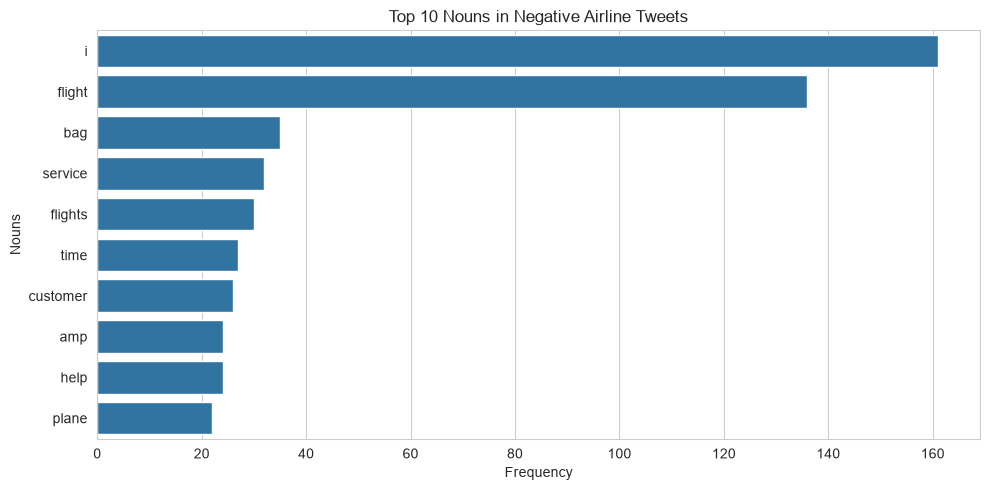

In [147]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_10_nouns.values,
    y=top_10_nouns.index
)

plt.title('Top 10 Nouns in Negative Airline Tweets')
plt.xlabel('Frequency')
plt.ylabel('Nouns')
plt.tight_layout()
plt.show()

## Compare with negativereason

In [148]:
top_reasons = negative_tweets['negativereason'].value_counts().head(5)

print("Top 5 Negative Reasons:")

display(top_reasons)

Top 5 Negative Reasons:


negativereason
Customer Service Issue     155
Can't Tell                  75
Late Flight                 54
Lost Luggage                52
Flight Booking Problems     44
Name: count, dtype: int64

# 5.5 How Does POS Tagging Work?
How POS Tagging Works
1. POS tagging identifies the grammatical role of each word in a sentence, such as noun, verb, adjective, or adverb.
2. POS tagging is difficult because the same word can have different grammatical roles depending on its context. For example, delay is a noun in "a long delay" but a verb in "they delay flights".
3. A rule-based tagger uses predefined grammar rules and dictionaries to assign tags to words.
4. A statistical tagger learns patterns from previously tagged text and predicts tags based on the surrounding words.
5. NLTK's default English pos_tag() uses a statistical Averaged Perceptron tagger.

## Check results

In [152]:
print("Heuristic Accuracy:", round(heuristic_accuracy, 4))
print("TextBlob Accuracy:", round(textblob_accuracy, 4))
print("Machine Learning Accuracy:", round(ml_accuracy, 4))

display(approach_comparison.round(4))

# Display POS tagging results
display(pos_df.head(5))

# Display top 10 nouns
display(top_10_nouns)

display(top_reasons)

print("completed successfully.")

Heuristic Accuracy: 0.402
TextBlob Accuracy: 0.444
Machine Learning Accuracy: 0.777


,Approach,Needs Training Data?,Accuracy,Macro F1,One Advantage,One Disadvantage
0,Heuristic,No,0.402,0.4275,Simple and easy to understand,Cannot understand context or sarcasm
1,TextBlob,No,0.444,0.4413,Ready-made and quick to use,May not understand airline-specific language
2,Machine Learning,Yes,0.777,0.7192,Learns sentiment patterns from training data,Requires labelled data and training


,Word,POS Tag
0,The,DT
1,flight,NN
2,arrived,VBD
3,early,JJ
4,and,CC


i           161
flight      136
bag          35
service      32
flights      30
time         27
customer     26
amp          24
help         24
plane        22
Name: count, dtype: int64

negativereason
Customer Service Issue     155
Can't Tell                  75
Late Flight                 54
Lost Luggage                52
Flight Booking Problems     44
Name: count, dtype: int64

completed successfully.


# 7.1 Results Summary Table

In [150]:
total_rows = df.shape[0]
total_columns = df.shape[1]

results_summary = {

    "Step / Topic": [
        "Step 1: RegEx & Preprocessing",
        "Step 2: BoW, TF-IDF & N-Grams",
        "Step 3: Word2Vec",
        "Step 4: Text Classification",
        "Step 5: Sentiment Approaches & POS",
        "Step 6: Streamlit Application"
    ],

    "Dataset Used": [
        f"Airline Tweets ({total_rows} rows)",
        f"Airline Tweets ({total_rows} rows)",
        f"Airline Tweets ({total_rows} rows)",
        f"Training and testing data from {total_rows} tweets",
        "1,000 test tweets + 500 negative tweets for noun analysis",
        "Individual airline customer tweets"
    ],

    "Key Technique": [
        "RegEx, lowercase, HTML cleaning, text preprocessing",
        "CountVectorizer, TfidfVectorizer, n-grams",
        "Gensim Word2Vec, CBOW, Skip-gram, PCA",
        "Logistic Regression, Word2Vec, Random Forest if evaluated",
        "Heuristic, TextBlob, NLTK POS tagging",
        "Streamlit, Joblib, trained ML pipeline"
    ],

    "Key Result": [
        "Cleaned text and extracted tweet information",
        "Vocabulary size: [Enter actual vocabulary size]",
        "Word2Vec vector size: 100; model trained with CBOW and Skip-gram",
        "Best model: [Enter model]; Accuracy: [Enter]; Macro F1: [Enter]",
        "Best approach: [Enter]; Top nouns: [Enter actual nouns]",
        "Application successfully predicts Negative, Neutral and Positive sentiment"
    ],

    "Time Taken (Minutes)": [
        0,  
        0,  
        0,  
        0,  
        0, 
        0  
    ]
}

# Create the results DataFrame
results_df = pd.DataFrame(results_summary)

# Display the summary table
display(results_df)


,Step / Topic,Dataset Used,Key Technique,Key Result,Time Taken (Minutes)
0,Step 1: RegEx & Preprocessing,Airline Tweets (14640 rows),"RegEx, lowercase, HTML cleaning, text preproce...",Cleaned text and extracted tweet information,0
1,"Step 2: BoW, TF-IDF & N-Grams",Airline Tweets (14640 rows),"CountVectorizer, TfidfVectorizer, n-grams",Vocabulary size: [Enter actual vocabulary size],0
2,Step 3: Word2Vec,Airline Tweets (14640 rows),"Gensim Word2Vec, CBOW, Skip-gram, PCA",Word2Vec vector size: 100; model trained with ...,0
3,Step 4: Text Classification,Training and testing data from 14640 tweets,"Logistic Regression, Word2Vec, Random Forest i...",Best model: [Enter model]; Accuracy: [Enter]; ...,0
4,Step 5: Sentiment Approaches & POS,"1,000 test tweets + 500 negative tweets for no...","Heuristic, TextBlob, NLTK POS tagging",Best approach: [Enter]; Top nouns: [Enter actu...,0
5,Step 6: Streamlit Application,Individual airline customer tweets,"Streamlit, Joblib, trained ML pipeline","Application successfully predicts Negative, Ne...",0


In [151]:
print("Dataset shape:", df.shape)
print("Total tweets:", len(df))

Dataset shape: (14640, 9)
Total tweets: 14640



## 7.2 Written Reflection

- **Most challenging step:** Step 6 (Streamlit Application) was the most challenging because I had to connect the trained machine learning pipeline with a user interface. I also faced issues with chart rendering, probability display and model integration. I resolved these issues and created an interactive application.

- **Accuracy and majority baseline:** Accuracy alone is not enough for this dataset because the sentiment classes are imbalanced. A model can achieve high accuracy by predicting the majority class while performing poorly on minority classes. The majority baseline helped me understand why macro precision, macro recall and macro F1-score are important evaluation metrics.

- **Best feature extraction method:** [Enter your best-performing method: BoW, TF-IDF, N-Grams or Word2Vec]. It performed best because [explain using your actual macro F1-score and model results]. TF-IDF and N-Grams can capture useful word importance and word combinations, while Word2Vec captures semantic relationships between words.

- **Importance of keeping "not" and "no":** I kept these words because they are important for understanding the actual meaning of a tweet. For example, "My flight was not comfortable" expresses negative sentiment. Removing "not" could change the meaning of the sentence.

- **Comparison of sentiment approaches:** The heuristic approach was simple and fast but depended on predefined positive and negative words. TextBlob provided a general-purpose polarity score, while the machine learning model learned patterns from the airline tweets dataset. [Enter which approach achieved the best macro F1-score]. I would still choose a simple heuristic approach for quick demonstrations or when computational resources are limited.

- **Sarcasm and Hinglish limitations:** The application sometimes struggled with sarcasm and Hinglish tweets such as "flight late hai, bakwaas service". This happens because the model was mainly trained on English airline tweets and may not understand mixed-language expressions, sarcasm or context correctly.

- **Future improvements:** I would improve this project by collecting more airline-related tweets, adding better text preprocessing, supporting Hinglish and other languages, and experimenting with Hugging Face Transformer models such as BERT or DistilBERT.

- **Overall learning:** This project helped me understand the complete NLP workflow, including text cleaning, feature extraction, Word2Vec embeddings, sentiment classification, model evaluation, POS tagging and deployment using Streamlit.
